In [1]:
import pandas as pd
import sqlite3

 
con = sqlite3.connect("C:\\Users\\jazee\\OneDrive\\Desktop\\ipl-cricket-analytics\\data\\raw\\ipl.db") 
  
def q(sql): 
    """Run a SELECT and show the result as a table.""" 
    return pd.read_sql(sql, con)


def run_sql_file(path): 
    """Read a .sql file and execute every statement in it.""" 
    with open(path, 'r') as f: 
        script = f.read() 
    con.executescript(script) 
    con.commit() 
    print('ran', path)

In [2]:
q("SELECT * FROM v_ball LIMIT 10;")

,season_id,match_id,batter,bowler,non_striker,over_number,ball_number,batter_runs,extras,total_runs,...,is_super_over,innings,batting_team_id,bowling_team_id,batting_team,bowling_team,phase,is_legal,bowler_runs,bowler_wicket
0,2008,335982,SC Ganguly,P Kumar,BB McCullum,0,0,0,1,1,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
1,2008,335982,BB McCullum,P Kumar,SC Ganguly,0,1,0,0,0,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
2,2008,335982,BB McCullum,P Kumar,SC Ganguly,0,2,0,1,1,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,0,1,0
3,2008,335982,BB McCullum,P Kumar,SC Ganguly,0,3,0,0,0,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
4,2008,335982,BB McCullum,P Kumar,SC Ganguly,0,4,0,0,0,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
5,2008,335982,BB McCullum,P Kumar,SC Ganguly,0,5,0,0,0,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
6,2008,335982,BB McCullum,P Kumar,SC Ganguly,0,6,0,1,1,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
7,2008,335982,BB McCullum,Z Khan,SC Ganguly,1,0,0,0,0,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
8,2008,335982,BB McCullum,Z Khan,SC Ganguly,1,1,4,0,4,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,4,0
9,2008,335982,BB McCullum,Z Khan,SC Ganguly,1,2,4,0,4,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,4,0


In [3]:
# Cell 1 — Display all data from v_ball

query = """
SELECT *
FROM v_ball
LIMIT 10;
"""

df = pd.read_sql_query(query, con)
df

,season_id,match_id,batter,bowler,non_striker,over_number,ball_number,batter_runs,extras,total_runs,...,is_super_over,innings,batting_team_id,bowling_team_id,batting_team,bowling_team,phase,is_legal,bowler_runs,bowler_wicket
0,2008,335982,SC Ganguly,P Kumar,BB McCullum,0,0,0,1,1,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
1,2008,335982,BB McCullum,P Kumar,SC Ganguly,0,1,0,0,0,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
2,2008,335982,BB McCullum,P Kumar,SC Ganguly,0,2,0,1,1,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,0,1,0
3,2008,335982,BB McCullum,P Kumar,SC Ganguly,0,3,0,0,0,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
4,2008,335982,BB McCullum,P Kumar,SC Ganguly,0,4,0,0,0,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
5,2008,335982,BB McCullum,P Kumar,SC Ganguly,0,5,0,0,0,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
6,2008,335982,BB McCullum,P Kumar,SC Ganguly,0,6,0,1,1,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
7,2008,335982,BB McCullum,Z Khan,SC Ganguly,1,0,0,0,0,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,0,0
8,2008,335982,BB McCullum,Z Khan,SC Ganguly,1,1,4,0,4,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,4,0
9,2008,335982,BB McCullum,Z Khan,SC Ganguly,1,2,4,0,4,...,0,1,6,1,Kolkata Knight Riders,Royal Challengers Bangalore,Powerplay,1,4,0


In [4]:
# Cell 2 — Display all innings data
# v_innings does not exist in your database, so we create the innings result directly.

query = """
SELECT
    match_id,
    innings,
    batting_team,
    SUM(total_runs) AS runs,
    SUM(is_legal) AS legal_balls,
    SUM(is_wicket) AS wickets
FROM v_ball
GROUP BY match_id, innings, batting_team
ORDER BY match_id, innings
LIMIT 10;
"""

df = pd.read_sql_query(query, con)
df

,match_id,innings,batting_team,runs,legal_balls,wickets
0,335982,1,Kolkata Knight Riders,222,120,3
1,335982,2,Royal Challengers Bangalore,82,91,10
2,335983,1,Chennai Super Kings,240,120,5
3,335983,2,Punjab Kings,207,120,4
4,335984,1,Rajasthan Royals,129,120,8
5,335984,2,Delhi Capitals,132,91,1
6,335985,1,Mumbai Indians,165,120,7
7,335985,2,Royal Challengers Bangalore,166,118,5
8,335986,1,Sunrisers Hyderabad,110,112,10
9,335986,2,Kolkata Knight Riders,112,114,5


In [5]:
# Cell 3 — Find the highest-scoring innings

query = """
SELECT
    match_id,
    innings,
    batting_team,
    SUM(total_runs) AS runs
FROM v_ball
GROUP BY match_id, innings, batting_team
ORDER BY runs DESC
LIMIT 10;
"""

df = pd.read_sql_query(query, con)
df

,match_id,innings,batting_team,runs
0,1426268,1,Sunrisers Hyderabad,287
1,1473439,1,Sunrisers Hyderabad,286
2,1473505,1,Sunrisers Hyderabad,278
3,1422126,1,Sunrisers Hyderabad,277
4,1422134,1,Kolkata Knight Riders,272
5,1426273,1,Sunrisers Hyderabad,266
6,1529278,2,Punjab Kings,265
7,1529278,1,Delhi Capitals,264
8,598027,1,Royal Challengers Bangalore,263
9,1426268,2,Royal Challengers Bangalore,262


In [6]:
# Cell 4 — Find average innings score

query = """
SELECT ROUND(AVG(runs), 2) AS average_score
FROM (
    SELECT
        match_id,
        innings,
        batting_team,
        SUM(total_runs) AS runs
    FROM v_ball
    GROUP BY match_id, innings, batting_team
);
"""

df = pd.read_sql_query(query, con)
df

,average_score
0,161.13


In [7]:
# Cell 5 — Find total runs scored by each team

query = """
SELECT
    batting_team,
    SUM(total_runs) AS total_runs
FROM v_ball
GROUP BY batting_team
ORDER BY total_runs DESC;
"""

df = pd.read_sql_query(query, con)
df

,batting_team,total_runs
0,Mumbai Indians,46517
1,Sunrisers Hyderabad,44948
2,Royal Challengers Bangalore,44890
3,Punjab Kings,44352
4,Delhi Capitals,43297
5,Chennai Super Kings,42557
6,Kolkata Knight Riders,42540
7,Rajasthan Royals,39159
8,Gujarat Titans,12196
9,Lucknow Super Giants,11509


In [8]:
# Cell 6 — Find average score of each team

query = """
SELECT
    batting_team,
    ROUND(AVG(runs), 2) AS average_score
FROM (
    SELECT
        match_id,
        innings,
        batting_team,
        SUM(total_runs) AS runs
    FROM v_ball
    GROUP BY match_id, innings, batting_team
)
GROUP BY batting_team
ORDER BY average_score DESC;
"""

df = pd.read_sql_query(query, con)
df

,batting_team,average_score
0,Gujarat Titans,176.75
1,Lucknow Super Giants,174.38
2,Chennai Super Kings,164.31
3,Punjab Kings,163.66
4,Mumbai Indians,163.22
5,Gujarat Lions,161.87
6,Sunrisers Hyderabad,161.10
7,Royal Challengers Bangalore,160.90
8,Rajasthan Royals,160.49
9,Delhi Capitals,157.44


In [9]:
# Cell 7 — Find teams with average score above 160

query = """
SELECT
    batting_team,
    ROUND(AVG(runs), 2) AS average_score
FROM (
    SELECT
        match_id,
        innings,
        batting_team,
        SUM(total_runs) AS runs
    FROM v_ball
    GROUP BY match_id, innings, batting_team
)
GROUP BY batting_team
HAVING AVG(runs) > 160
ORDER BY average_score DESC;
"""

df = pd.read_sql_query(query, con)
df

,batting_team,average_score
0,Gujarat Titans,176.75
1,Lucknow Super Giants,174.38
2,Chennai Super Kings,164.31
3,Punjab Kings,163.66
4,Mumbai Indians,163.22
5,Gujarat Lions,161.87
6,Sunrisers Hyderabad,161.10
7,Royal Challengers Bangalore,160.90
8,Rajasthan Royals,160.49


In [10]:
# Cell 8 — Find the highest-scoring team innings

query = """
SELECT
    batting_team,
    MAX(runs) AS highest_score
FROM (
    SELECT
        match_id,
        innings,
        batting_team,
        SUM(total_runs) AS runs
    FROM v_ball
    GROUP BY match_id, innings, batting_team
)
GROUP BY batting_team
ORDER BY highest_score DESC;
"""

df = pd.read_sql_query(query, con)
df

,batting_team,highest_score
0,Sunrisers Hyderabad,287
1,Kolkata Knight Riders,272
2,Punjab Kings,265
3,Delhi Capitals,264
4,Royal Challengers Bangalore,263
5,Lucknow Super Giants,257
6,Mumbai Indians,247
7,Chennai Super Kings,246
8,Rajasthan Royals,242
9,Gujarat Titans,233


In [11]:
# Cell 9 — Count innings played by each team

query = """
SELECT
    batting_team,
    COUNT(*) AS innings_count
FROM (
    SELECT
        match_id,
        innings,
        batting_team
    FROM v_ball
    GROUP BY match_id, innings, batting_team
)
GROUP BY batting_team
ORDER BY innings_count DESC;
"""

df = pd.read_sql_query(query, con)
df

,batting_team,innings_count
0,Mumbai Indians,285
1,Sunrisers Hyderabad,279
2,Royal Challengers Bangalore,279
3,Delhi Capitals,275
4,Kolkata Knight Riders,272
5,Punjab Kings,271
6,Chennai Super Kings,259
7,Rajasthan Royals,244
8,Gujarat Titans,69
9,Lucknow Super Giants,66


In [12]:
# Cell 10 — Find matches where the first innings score was above 200

query = """
WITH innings_scores AS (
    SELECT
        match_id,
        innings,
        batting_team,
        SUM(total_runs) AS runs
    FROM v_ball
    GROUP BY match_id, innings, batting_team
)
SELECT
    i.match_id,
    i.runs AS first_innings_runs,
    i.batting_team AS bat_first_team,
    m.match_winner
FROM innings_scores i
LEFT JOIN v_matches_clean m
    ON i.match_id = m.match_id
WHERE i.innings = 1
  AND i.runs > 200
ORDER BY i.runs DESC;
"""

df = pd.read_sql_query(query, con)
df

,match_id,first_innings_runs,bat_first_team,match_winner
0,1426268,287,Sunrisers Hyderabad,Sunrisers Hyderabad
1,1473439,286,Sunrisers Hyderabad,Sunrisers Hyderabad
2,1473505,278,Sunrisers Hyderabad,Sunrisers Hyderabad
3,1422126,277,Sunrisers Hyderabad,Sunrisers Hyderabad
4,1422134,272,Kolkata Knight Riders,Kolkata Knight Riders
...,...,...,...,...
186,1216547,201,Royal Challengers Bangalore,Mumbai Indians
187,1426288,201,Sunrisers Hyderabad,Sunrisers Hyderabad
188,1473481,201,Punjab Kings,Kolkata Knight Riders
189,1527674,201,Sunrisers Hyderabad,Royal Challengers Bangalore


In [13]:
# Cell 11 — Find the biggest first-innings score

query = """
SELECT
    MAX(runs) AS highest_first_innings_score
FROM (
    SELECT
        match_id,
        SUM(total_runs) AS runs
    FROM v_ball
    WHERE innings = 1
    GROUP BY match_id, innings
);
"""

df = pd.read_sql_query(query, con)
df

,highest_first_innings_score
0,287


In [14]:
# Cell 12 — Count wins by team

query = """
SELECT
    match_winner,
    COUNT(*) AS wins
FROM v_matches_clean
WHERE match_winner IS NOT NULL
GROUP BY match_winner
ORDER BY wins DESC;
"""

df = pd.read_sql_query(query, con)
df

,match_winner,wins
0,Mumbai Indians,155
1,Chennai Super Kings,146
2,Royal Challengers Bangalore,139
3,Kolkata Knight Riders,137
4,Sunrisers Hyderabad,132
5,Punjab Kings,130
6,Delhi Capitals,126
7,Rajasthan Royals,125
8,Gujarat Titans,42
9,Lucknow Super Giants,33


In [15]:
# Cell 13 — Calculate chase-win percentage

query = """
WITH innings_scores AS (
    SELECT
        match_id,
        innings,
        batting_team,
        SUM(total_runs) AS runs
    FROM v_ball
    GROUP BY match_id, innings, batting_team
),
match_scores AS (
    SELECT
        match_id,
        MAX(CASE WHEN innings = 1 THEN batting_team END) AS first_team,
        MAX(CASE WHEN innings = 2 THEN batting_team END) AS chasing_team
    FROM innings_scores
    GROUP BY match_id
)
SELECT
    ROUND(
        100.0 * AVG(
            CASE
                WHEN m.match_winner = s.chasing_team THEN 1.0
                ELSE 0.0
            END
        ),
        2
    ) AS chase_win_percentage
FROM match_scores s
JOIN v_matches_clean m
    ON s.match_id = m.match_id
WHERE s.chasing_team IS NOT NULL
  AND m.match_winner IS NOT NULL;
"""

df = pd.read_sql_query(query, con)
df

,chase_win_percentage
0,54.73


In [16]:
# Cell 14 — Find the best venues for chasing

query = """
WITH innings_scores AS (
    SELECT
        match_id,
        innings,
        batting_team,
        SUM(total_runs) AS runs
    FROM v_ball
    GROUP BY match_id, innings, batting_team
),
match_scores AS (
    SELECT
        match_id,
        MAX(CASE WHEN innings = 2 THEN batting_team END) AS chasing_team
    FROM innings_scores
    GROUP BY match_id
)
SELECT
    m.venue_clean,
    COUNT(*) AS matches,
    ROUND(
        100.0 * AVG(
            CASE
                WHEN m.match_winner = s.chasing_team THEN 1.0
                ELSE 0.0
            END
        ),
        2
    ) AS chase_win_percentage
FROM match_scores s
JOIN v_matches_clean m
    ON s.match_id = m.match_id
WHERE s.chasing_team IS NOT NULL
  AND m.match_winner IS NOT NULL
GROUP BY m.venue_clean
HAVING COUNT(*) >= 30
ORDER BY chase_win_percentage DESC
LIMIT 10;
"""

df = pd.read_sql_query(query, con)
df

,venue_clean,matches,chase_win_percentage
0,Sawai Mansingh Stadium,66,65.15
1,Eden Gardens,103,58.25
2,Punjab Cricket Association Stadium,35,57.14
3,Wankhede Stadium,130,55.38
4,M Chinnaswamy Stadium,103,55.34
5,Rajiv Gandhi International Stadium,86,54.65
6,Dubai International Cricket Stadium,46,54.35
7,Feroz Shah Kotla,59,54.24
8,Dr DY Patil Sports Academy,37,54.05
9,Narendra Modi Stadium,37,51.35


In [17]:
# Cell 15 — Find runs scored in each innings phase

query = """
SELECT
    phase,
    SUM(total_runs) AS total_runs
FROM v_ball
GROUP BY phase
ORDER BY total_runs DESC;
"""

df = pd.read_sql_query(query, con)
df

,phase,total_runs
0,Middle,169160
1,Powerplay,116397
2,Death,104056


In [18]:
query = """
SELECT batter,
       SUM(is_legal) AS balls,
       ROUND(100.0 * SUM(batter_runs) / SUM(is_legal), 2) AS sr_pp,
       SUM(CASE WHEN player_out = batter THEN 1 ELSE 0 END) AS times_out_in_pp
FROM v_ball
WHERE phase = 'Powerplay'
GROUP BY batter
HAVING balls >= 600 AND sr_pp >= 140
ORDER BY sr_pp DESC
LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,batter,balls,sr_pp,times_out_in_pp
0,Abhishek Sharma,744,172.98,31
1,SP Narine,688,170.64,48
2,YBK Jaiswal,984,160.47,36
3,P Simran Singh,687,155.75,27
4,JM Bairstow,623,151.52,19


In [19]:
query = """
SELECT bowler,
       ROUND(
           6.0 * SUM(
               CASE WHEN phase = 'Powerplay'
                    THEN bowler_runs ELSE 0 END
           ) / NULLIF(
               SUM(
                   CASE WHEN phase = 'Powerplay'
                        THEN is_legal ELSE 0 END
               ), 0
           ), 2
       ) AS pp,

       ROUND(
           6.0 * SUM(
               CASE WHEN phase = 'Middle'
                    THEN bowler_runs ELSE 0 END
           ) / NULLIF(
               SUM(
                   CASE WHEN phase = 'Middle'
                        THEN is_legal ELSE 0 END
               ), 0
           ), 2
       ) AS mid,

       ROUND(
           6.0 * SUM(
               CASE WHEN phase = 'Death'
                    THEN bowler_runs ELSE 0 END
           ) / NULLIF(
               SUM(
                   CASE WHEN phase = 'Death'
                        THEN is_legal ELSE 0 END
               ), 0
           ), 2
       ) AS death

FROM v_ball

GROUP BY bowler

HAVING SUM(
           CASE WHEN phase = 'Powerplay'
                THEN is_legal ELSE 0 END
       ) >= 300
   AND SUM(
           CASE WHEN phase = 'Middle'
                THEN is_legal ELSE 0 END
       ) >= 300
   AND SUM(
           CASE WHEN phase = 'Death'
                THEN is_legal ELSE 0 END
       ) >= 300
   AND pp < 8
   AND mid < 8
   AND death < 9

ORDER BY (pp + mid + death) ASC

LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,bowler,pp,mid,death
0,SP Narine,6.86,6.55,7.29
1,DW Steyn,6.26,6.57,8.30
2,SL Malinga,6.28,7.41,7.86
3,JJ Bumrah,6.85,6.59,8.23
4,R Ashwin,7.09,7.03,8.24


In [20]:
query = """
SELECT batter,
       SUM(is_legal) AS balls,
       ROUND(
           100.0 * SUM(batter_runs) / SUM(is_legal), 2
       ) AS sr

FROM v_ball

WHERE innings = 2
  AND phase = 'Death'

GROUP BY batter

HAVING balls >= 200

ORDER BY sr DESC

LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,batter,balls,sr
0,AB de Villiers,295,209.83
1,SS Iyer,215,187.44
2,DA Miller,439,186.33
3,RR Pant,214,185.51
4,SV Samson,207,183.57


In [21]:
query = """
SELECT bowler,
       SUM(is_legal) AS balls,
       ROUND(
           6.0 * SUM(bowler_runs) / SUM(is_legal), 2
       ) AS economy

FROM v_ball

WHERE phase = 'Powerplay'
  AND (
       bowler_type LIKE '%Legbreak%'
       OR bowler_type LIKE '%Offbreak%'
       OR bowler_type LIKE '%Orthodox%'
       OR bowler_type LIKE '%Googly%'
       OR bowler_type LIKE '%Wrist spin%'
  )

GROUP BY bowler

HAVING balls >= 200

ORDER BY economy ASC

LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,bowler,balls,economy
0,Iqbal Abdulla,276,6.33
1,YK Pathan,354,6.69
2,SP Narine,954,6.86
3,R Ashwin,1252,7.09
4,Harbhajan Singh,773,7.10


In [22]:
query = """
SELECT b.batter,
       SUM(b.batter_runs) AS middle_runs,
       ROUND(
           100.0 * SUM(b.batter_runs) / SUM(b.is_legal), 2
       ) AS sr,
       SUM(
           CASE WHEN b.player_out = b.batter
                THEN 1 ELSE 0 END
       ) AS outs_in_middle,
       ROUND(
           1.0 * SUM(b.batter_runs) /
           NULLIF(
               SUM(
                   CASE WHEN b.player_out = b.batter
                        THEN 1 ELSE 0 END
               ), 0
           ), 2
       ) AS average

FROM v_ball b

WHERE b.phase = 'Middle'

GROUP BY b.batter

HAVING SUM(b.is_legal) >= 500
   AND sr >= 140
   AND average >= 25

ORDER BY sr DESC

LIMIT 8;
"""

df = pd.read_sql_query(query, con)
df

,batter,middle_runs,sr,outs_in_middle,average
0,V Sehwag,1062,173.81,33,32.18
1,RM Patidar,970,171.38,25,38.80
2,N Pooran,1351,159.32,37,36.51
3,H Klaasen,1099,157.68,15,73.27
4,CH Gayle,2011,156.50,45,44.69
5,AD Russell,1182,154.11,34,34.76
6,SR Watson,2006,154.07,60,33.43
7,GJ Maxwell,1780,153.05,65,27.38


In [23]:
query = """
SELECT batter,
       ROUND(
           100.0 * SUM(
               CASE WHEN innings = 1
                    THEN batter_runs ELSE 0 END
           ) / NULLIF(
               SUM(
                   CASE WHEN innings = 1
                        THEN is_legal ELSE 0 END
               ), 0
           ), 1
       ) AS sr_first,

       ROUND(
           100.0 * SUM(
               CASE WHEN innings = 2
                    THEN batter_runs ELSE 0 END
           ) / NULLIF(
               SUM(
                   CASE WHEN innings = 2
                        THEN is_legal ELSE 0 END
               ), 0
           ), 1
       ) AS sr_second

FROM v_ball

GROUP BY batter

HAVING SUM(
           CASE WHEN innings = 1
                THEN is_legal ELSE 0 END
       ) >= 800
   AND SUM(
           CASE WHEN innings = 2
                THEN is_legal ELSE 0 END
       ) >= 800
   AND sr_first >= 135
   AND sr_second >= 135

ORDER BY (sr_first + sr_second) DESC

LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,batter,sr_first,sr_second
0,V Sehwag,149.4,164.2
1,JC Buttler,144.3,156.7
2,AB de Villiers,162.7,138.1
3,SA Yadav,144.5,154.2
4,CH Gayle,154.0,144.0


In [24]:
# L1 — Has scoring gone up across the seasons?

query = """
SELECT m.season_year,
       ROUND(
           AVG(match_runs), 1
       ) AS avg_innings_score

FROM (
    SELECT match_id,
           innings,
           SUM(total_runs) AS match_runs
    FROM v_ball
    GROUP BY match_id, innings
) AS i

JOIN matches_clean m
  ON i.match_id = m.match_id

GROUP BY m.season_year

ORDER BY m.season_year DESC

LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,season_year,avg_innings_score
0,2026,184.0
1,2025,181.5
2,2024,182.9
3,2023,174.7
4,2022,164.8


In [25]:
# L2 — Has the six become more common?

query = """
SELECT m.season_year,
       ROUND(
           100.0 * SUM(
               CASE
                   WHEN b.batter_runs = 6
                   THEN 1
                   ELSE 0
               END
           ) / SUM(b.is_legal), 2
       ) AS six_pct

FROM v_ball b

JOIN matches_clean m
  ON m.match_id = b.match_id

GROUP BY m.season_year

ORDER BY m.season_year DESC

LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,season_year,six_pct
0,2026,8.30
1,2025,7.88
2,2024,7.74
3,2023,6.56
4,2022,6.20


In [26]:
# L3 — Has the dot-ball rate fallen?

query = """
SELECT m.season_year,
       ROUND(
           100.0 * SUM(
               CASE
                   WHEN b.total_runs = 0
                    AND b.is_legal = 1
                   THEN 1
                   ELSE 0
               END
           ) / SUM(b.is_legal), 2
       ) AS dot_pct

FROM v_ball b

JOIN matches_clean m
  ON m.match_id = b.match_id

GROUP BY m.season_year

ORDER BY m.season_year DESC

LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,season_year,dot_pct
0,2026,32.45
1,2025,32.34
2,2024,32.93
3,2023,33.94
4,2022,37.08


In [27]:
# L4 — How many matches were played each season?

query = """
SELECT season_year,
       COUNT(*) AS matches

FROM matches_clean

GROUP BY season_year

ORDER BY matches DESC

LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,season_year,matches
0,2013,76
1,2025,74
2,2023,74
3,2022,74
4,2012,74


In [28]:
# L5 — Has the death-overs run rate changed?

query = """
SELECT m.season_year,
       ROUND(
           6.0 * SUM(b.total_runs) / SUM(b.is_legal), 2
       ) AS death_run_rate

FROM v_ball b

JOIN matches_clean m
  ON m.match_id = b.match_id

WHERE b.phase = 'Death'

GROUP BY m.season_year

ORDER BY m.season_year DESC

LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,season_year,death_run_rate
0,2026,10.63
1,2025,10.96
2,2024,11.21
3,2023,10.49
4,2022,10.45


In [29]:
# L6 — Which season had the highest-scoring matches?

query = """
WITH per_match AS (
    SELECT match_id,
           SUM(total_runs) AS runs
    FROM v_ball
    GROUP BY match_id
)

SELECT m.season_year,
       ROUND(AVG(p.runs), 1) AS avg_match_runs

FROM per_match p

JOIN matches_clean m
  ON m.match_id = p.match_id

GROUP BY m.season_year

ORDER BY avg_match_runs DESC

LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,season_year,avg_match_runs
0,2024,365.8
1,2026,363.7
2,2025,358.1
3,2023,347.1
4,2018,331.7


In [30]:
# L7 — Are spinners bowling more or fewer overs than they used to?

query = """
SELECT m.season_year,
       ROUND(
           100.0 * SUM(
               CASE
                   WHEN b.bowler_type LIKE '%Legbreak%'
                     OR b.bowler_type LIKE '%Offbreak%'
                     OR b.bowler_type LIKE '%Orthodox%'
                     OR b.bowler_type LIKE '%Googly%'
                     OR b.bowler_type LIKE '%Wrist spin%'
                   THEN b.is_legal
                   ELSE 0
               END
           ) / SUM(b.is_legal), 1
       ) AS pct_balls_spin

FROM v_ball b

JOIN matches_clean m
  ON m.match_id = b.match_id

GROUP BY m.season_year

ORDER BY m.season_year DESC

LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,season_year,pct_balls_spin
0,2026,31.3
1,2025,38.3
2,2024,33.6
3,2023,41.9
4,2022,35.2


In [31]:
# L8 — Season on season, how much did the average score change?

query = """
WITH per_season AS (
    SELECT m.season_year AS yr,
           AVG(i.runs) AS avg_runs
    FROM matches_clean m
    JOIN (
        SELECT match_id,
               innings,
               SUM(total_runs) AS runs
        FROM v_ball
        GROUP BY match_id, innings
    ) AS i
      ON i.match_id = m.match_id
    GROUP BY m.season_year
)

SELECT yr,
       ROUND(avg_runs, 1) AS avg_runs,
       ROUND(
           avg_runs - LAG(avg_runs) OVER (ORDER BY yr), 1
       ) AS change_from_last_season

FROM per_season

ORDER BY yr DESC

LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,yr,avg_runs,change_from_last_season
0,2026,184.0,2.5
1,2025,181.5,-1.4
2,2024,182.9,8.1
3,2023,174.7,9.9
4,2022,164.8,9.6


In [32]:
# K1 — How often does a wicket fall, per ball?

query = """
SELECT
       ROUND(
           100.0 * SUM(is_wicket) / SUM(is_legal), 2
       ) AS wicket_pct_per_ball,

       ROUND(
           1.0 * SUM(is_legal) / SUM(is_wicket), 1
       ) AS balls_per_wicket

FROM v_ball;
"""

df = pd.read_sql_query(query, con)
df

,wicket_pct_per_ball,balls_per_wicket
0,5.16,19.4


In [33]:
# K2 — Which fielder has been involved in the most dismissals? (a trap)

query = """
SELECT fielders_involved,
       COUNT(*) AS n
FROM v_ball
WHERE is_wicket = 1
GROUP BY fielders_involved
ORDER BY n DESC
LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,fielders_involved,n
0,[None],3892
1,['MS Dhoni'],221
2,['KD Karthik'],191
3,['AB de Villiers'],134
4,['V Kohli'],131


In [34]:
# K3 — How does the way batters get out change across the phases?

query = """
SELECT phase,
       wicket_kind,
       COUNT(*) AS n
FROM v_ball
WHERE is_wicket = 1
  AND wicket_kind IN ('caught', 'bowled', 'run out')
GROUP BY phase, wicket_kind
ORDER BY phase, n DESC;
"""

df = pd.read_sql_query(query, con)
df

,phase,wicket_kind,n
0,Death,caught,3289
1,Death,bowled,877
2,Death,run out,634
3,Middle,caught,3484
4,Middle,bowled,909
5,Middle,run out,344
6,Powerplay,caught,2272
7,Powerplay,bowled,612
8,Powerplay,run out,189


In [35]:
# K4 — Which batter is most often run out?

query = """
SELECT player_out,
       COUNT(*) AS run_outs
FROM v_ball
WHERE wicket_kind = 'run out'
GROUP BY player_out
ORDER BY run_outs DESC
LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,player_out,run_outs
0,S Dhawan,16
1,G Gambhir,16
2,SK Raina,15
3,KD Karthik,15
4,AT Rayudu,15


In [36]:
# K5 — Which bowler dismisses a named batter most often?

query = """
SELECT bowler,
       COUNT(*) AS times_out
FROM v_ball
WHERE player_out = 'V Kohli'
  AND bowler_wicket = 1
GROUP BY bowler
ORDER BY times_out DESC
LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,bowler,times_out
0,Sandeep Sharma,7
1,A Nehra,6
2,JJ Bumrah,5
3,Mohammed Shami,5
4,Avesh Khan,4


In [37]:
# K6 — How many wickets fall in a typical innings?

query = """
SELECT
       ROUND(AVG(wickets), 2) AS avg_wickets_per_innings
FROM (
    SELECT match_id,
           innings,
           SUM(is_wicket) AS wickets
    FROM v_ball
    GROUP BY match_id, innings
);
"""

df = pd.read_sql_query(query, con)
df

,avg_wickets_per_innings
0,5.92


In [38]:
# K7 — Do teams that lose early wickets still post a good score?

query = """
WITH pp AS (
    SELECT match_id,
           innings,
           SUM(is_wicket) AS pp_wkts
    FROM v_ball
    WHERE phase = 'Powerplay'
    GROUP BY match_id, innings
)
SELECT pp.pp_wkts AS wickets_lost_in_powerplay,
       COUNT(*) AS innings_count,
       ROUND(AVG(i.runs), 1) AS avg_final_score
FROM pp
JOIN (
    SELECT match_id,
           innings,
           SUM(total_runs) AS runs
    FROM v_ball
    GROUP BY match_id, innings
) AS i
  ON i.match_id = pp.match_id
 AND i.innings = pp.innings
GROUP BY pp.pp_wkts
ORDER BY pp.pp_wkts
LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,wickets_lost_in_powerplay,innings_count,avg_final_score
0,0,526,171.3
1,1,846,168.0
2,2,639,155.9
3,3,296,148.1
4,4,88,128.3


In [39]:
# K8 — What share of dismissals are caught?

query = """
SELECT
       ROUND(
           100.0 * SUM(
               CASE
                   WHEN wicket_kind IN ('caught', 'caught and bowled')
                   THEN 1
                   ELSE 0
               END
           ) / COUNT(*), 2
       ) AS pct_caught
FROM v_ball
WHERE is_wicket = 1;
"""

df = pd.read_sql_query(query, con)
df

,pct_caught
0,66.0


In [40]:
# J3 — Which team scores fastest in the powerplay?

query = """
SELECT batting_team,
       ROUND(
           6.0 * SUM(total_runs) / SUM(is_legal), 2
       ) AS pp_run_rate
FROM v_ball
WHERE phase = 'Powerplay'
GROUP BY batting_team
HAVING SUM(is_legal) >= 3000
ORDER BY pp_run_rate DESC
LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,batting_team,pp_run_rate
0,Punjab Kings,8.21
1,Sunrisers Hyderabad,8.20
2,Rajasthan Royals,8.07
3,Delhi Capitals,8.03
4,Kolkata Knight Riders,8.02


In [41]:
# J4 — Which team has the best death-overs bowling?

query = """
SELECT bowling_team,
       ROUND(
           6.0 * SUM(bowler_runs) / SUM(is_legal), 2
       ) AS death_economy
FROM v_ball
WHERE phase = 'Death'
GROUP BY bowling_team
HAVING SUM(is_legal) >= 2000
ORDER BY death_economy ASC
LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,bowling_team,death_economy
0,Chennai Super Kings,9.53
1,Mumbai Indians,9.54
2,Kolkata Knight Riders,9.55
3,Sunrisers Hyderabad,9.83
4,Delhi Capitals,9.87


In [42]:
# J6 — Which team is best at defending a total?

query = """
WITH match_totals AS (
    SELECT match_id,
           innings,
           batting_team,
           SUM(total_runs) AS total_runs
    FROM v_ball
    GROUP BY match_id, innings, batting_team
),
first_innings AS (
    SELECT match_id,
           batting_team AS bat_first_team,
           total_runs AS first_innings_runs
    FROM match_totals
    WHERE innings = 1
),
second_innings AS (
    SELECT match_id,
           batting_team AS chasing_team,
           total_runs AS second_innings_runs
    FROM match_totals
    WHERE innings = 2
)
SELECT f.bat_first_team,
       COUNT(*) AS defended_innings,
       ROUND(
           100.0 * SUM(
               CASE
                   WHEN s.second_innings_runs < f.first_innings_runs
                   THEN 1
                   ELSE 0
               END
           ) / COUNT(*), 1
       ) AS defence_win_pct
FROM first_innings f
JOIN second_innings s
  ON f.match_id = s.match_id
GROUP BY f.bat_first_team
HAVING COUNT(*) >= 50
ORDER BY defence_win_pct DESC
LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,bat_first_team,defended_innings,defence_win_pct
0,Mumbai Indians,147,53.1
1,Chennai Super Kings,142,52.8
2,Sunrisers Hyderabad,152,47.4
3,Royal Challengers Bangalore,142,45.8
4,Kolkata Knight Riders,130,43.8


In [43]:
# J7 — Which team relies most on boundaries for its runs?

query = """
SELECT batting_team,
       ROUND(
           100.0 * SUM(
               CASE
                   WHEN batter_runs IN (4, 6)
                   THEN batter_runs
                   ELSE 0
               END
           ) / SUM(batter_runs), 2
       ) AS pct_from_boundaries
FROM v_ball
GROUP BY batting_team
HAVING SUM(is_legal) >= 10000
ORDER BY pct_from_boundaries DESC
LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,batting_team,pct_from_boundaries
0,Mumbai Indians,62.30
1,Kolkata Knight Riders,61.84
2,Punjab Kings,61.67
3,Royal Challengers Bangalore,61.44
4,Rajasthan Royals,60.90


In [44]:
# I1 — Which ground has hosted the most matches?

query = """
PRAGMA table_info(matches_clean);
"""

df = pd.read_sql_query(query, con)
df

,cid,name,type,notnull,dflt_value,pk
0,0,match_id,INT,0,None,0
1,1,season_id,INT,0,None,0
2,2,balls_per_over,INT,0,None,0
3,3,city,TEXT,0,None,0
4,4,match_date,TEXT,0,None,0
5,5,event_name,TEXT,0,None,0
6,6,match_number,REAL,0,None,0
7,7,gender,TEXT,0,None,0
8,8,match_type,TEXT,0,None,0
9,9,format,TEXT,0,None,0


In [45]:
# I2 — Which ground is the highest scoring?

query = """
PRAGMA table_info(matches_clean);
"""

df = pd.read_sql_query(query, con)
df

,cid,name,type,notnull,dflt_value,pk
0,0,match_id,INT,0,None,0
1,1,season_id,INT,0,None,0
2,2,balls_per_over,INT,0,None,0
3,3,city,TEXT,0,None,0
4,4,match_date,TEXT,0,None,0
5,5,event_name,TEXT,0,None,0
6,6,match_number,REAL,0,None,0
7,7,gender,TEXT,0,None,0
8,8,match_type,TEXT,0,None,0
9,9,format,TEXT,0,None,0


In [46]:
# I3 — Which ground favours the chasing team?

query = """
PRAGMA table_info(matches_clean);
"""

df = pd.read_sql_query(query, con)
df

,cid,name,type,notnull,dflt_value,pk
0,0,match_id,INT,0,None,0
1,1,season_id,INT,0,None,0
2,2,balls_per_over,INT,0,None,0
3,3,city,TEXT,0,None,0
4,4,match_date,TEXT,0,None,0
5,5,event_name,TEXT,0,None,0
6,6,match_number,REAL,0,None,0
7,7,gender,TEXT,0,None,0
8,8,match_type,TEXT,0,None,0
9,9,format,TEXT,0,None,0


In [47]:
# I4 — Which ground helps the spinners most?

query = """
PRAGMA table_info(matches_clean);
"""

df = pd.read_sql_query(query, con)
df

,cid,name,type,notnull,dflt_value,pk
0,0,match_id,INT,0,None,0
1,1,season_id,INT,0,None,0
2,2,balls_per_over,INT,0,None,0
3,3,city,TEXT,0,None,0
4,4,match_date,TEXT,0,None,0
5,5,event_name,TEXT,0,None,0
6,6,match_number,REAL,0,None,0
7,7,gender,TEXT,0,None,0
8,8,match_type,TEXT,0,None,0
9,9,format,TEXT,0,None,0


In [48]:
# I5 — How many separate grounds has the IPL been played at?

query = """
SELECT COUNT(DISTINCT venue)
AS grounds
FROM matches_clean;
"""

df = pd.read_sql_query(query, con)
df

,grounds
0,59


In [49]:
# I6 — Which ground has the lowest average score?

query = """
SELECT venue,
       ROUND(AVG(runs), 1) AS avg_score
FROM (
    SELECT m.venue,
           b.match_id,
           b.innings,
           SUM(b.total_runs) AS runs
    FROM v_ball b
    JOIN matches_clean m
      ON m.match_id = b.match_id
    GROUP BY m.venue, b.match_id, b.innings
)
GROUP BY venue
ORDER BY avg_score ASC
LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,venue,avg_score
0,Newlands,126.0
1,OUTsurance Oval,132.3
2,Buffalo Park,133.2
3,Nehru Stadium,136.3
4,Dr DY Patil Sports Academy,141.5


In [50]:
# I7 — Does the powerplay behave differently at different grounds?

query = """
SELECT m.venue,
       ROUND(
           6.0 * SUM(b.total_runs) / SUM(b.is_legal), 2
       ) AS pp_run_rate,
       COUNT(DISTINCT m.match_id) AS matches
FROM v_ball b
JOIN matches_clean m
  ON m.match_id = b.match_id
WHERE b.phase = 'Powerplay'
GROUP BY m.venue
HAVING COUNT(DISTINCT m.match_id) >= 25
ORDER BY pp_run_rate DESC
LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,venue,pp_run_rate,matches
0,"Eden Gardens, Kolkata",10.02,27
1,"Arun Jaitley Stadium, Delhi",9.92,27
2,"Narendra Modi Stadium, Ahmedabad",8.90,37
3,"MA Chidambaram Stadium, Chepauk, Chennai",8.50,38
4,"Wankhede Stadium, Mumbai",8.49,57


In [51]:
# I8 — Can we compare day matches with night matches?

query = """
SELECT COUNT(*) AS matches,
       COUNT(match_date) AS have_a_date
FROM matches_clean;
"""

df = pd.read_sql_query(query, con)
df

,matches,have_a_date
0,1212,1212


In [52]:
# I9 — Which ground has the most matches?

query = """
SELECT venue,
       COUNT(*) AS matches
FROM matches_clean
GROUP BY venue
ORDER BY matches DESC
LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,venue,matches
0,Eden Gardens,77
1,Wankhede Stadium,73
2,M Chinnaswamy Stadium,65
3,Feroz Shah Kotla,60
4,"Wankhede Stadium, Mumbai",57


In [53]:
# H1 — Overall, is it better to bat first or to chase?

query = """
WITH match_totals AS (
    SELECT match_id,
           innings,
           SUM(total_runs) AS runs
    FROM v_ball
    GROUP BY match_id, innings
),
results AS (
    SELECT f.match_id,
           CASE
               WHEN s.runs > f.runs THEN 1
               ELSE 0
           END AS chase_won
    FROM match_totals f
    JOIN match_totals s
      ON f.match_id = s.match_id
    WHERE f.innings = 1
      AND s.innings = 2
)
SELECT COUNT(*) AS matches,
       SUM(chase_won) AS chases_won,
       ROUND(100.0 * AVG(chase_won), 2) AS chase_win_pct
FROM results;
"""

df = pd.read_sql_query(query, con)
df

,matches,chases_won,chase_win_pct
0,1206,633,52.49


In [54]:
# H2 — What first-innings total is worth defending?

query = """
WITH m AS (
    SELECT match_id,
           innings,
           SUM(total_runs) AS runs
    FROM v_ball
    GROUP BY match_id, innings
)
SELECT CASE
    WHEN a.runs < 140 THEN 'Under 140'
    WHEN a.runs < 160 THEN '140-159'
    WHEN a.runs < 180 THEN '160-179'
    WHEN a.runs < 200 THEN '180-199'
    ELSE '200+'
END AS target_band,
COUNT(*) AS matches,
ROUND(100.0 * AVG(CASE WHEN b.runs > a.runs THEN 1.0 ELSE 0.0 END),1) AS chase_win_pct
FROM m a
JOIN m b ON a.match_id = b.match_id
WHERE a.innings = 1 AND b.innings = 2
GROUP BY target_band
ORDER BY MIN(a.runs);
"""

df = pd.read_sql_query(query, con)
df

,target_band,matches,chase_win_pct
0,Under 140,222,77.9
1,140-159,248,67.3
2,160-179,315,52.7
3,180-199,221,37.1
4,200+,200,22.5


In [55]:
# H3 — What is the average first-innings score?

query = """
SELECT ROUND(AVG(runs), 1) AS avg_first_innings
FROM (
    SELECT match_id,
           SUM(total_runs) AS runs
    FROM v_ball
    WHERE innings = 1
    GROUP BY match_id
);
"""

df = pd.read_sql_query(query, con)
df

,avg_first_innings
0,167.8


In [56]:
# H4 — Where is the break-even total — the score at which the game is even?

query = """
WITH m AS (
    SELECT match_id,
           innings,
           SUM(total_runs) AS runs
    FROM v_ball
    GROUP BY match_id, innings
)
SELECT CASE
    WHEN a.runs < 155 THEN 'Under 155'
    WHEN a.runs < 165 THEN '155-164'
    WHEN a.runs < 175 THEN '165-174'
    ELSE '175+'
END AS band,
COUNT(*) AS matches,
ROUND(100.0 * AVG(
    CASE WHEN b.runs > a.runs THEN 1.0 ELSE 0.0 END
), 1) AS chase_win_pct
FROM m a
JOIN m b ON a.match_id = b.match_id
WHERE a.innings = 1
  AND b.innings = 2
GROUP BY band
ORDER BY MIN(a.runs);
"""

df = pd.read_sql_query(query, con)
df

,band,matches,chase_win_pct
0,Under 155,392,74.2
1,155-164,171,60.2
2,165-174,147,48.3
3,175+,496,33.9


In [57]:
# H5 — Do chasing teams score faster than teams batting first?

query = """
SELECT innings,
       ROUND(6.0 * SUM(total_runs) / SUM(is_legal), 2) AS run_rate
FROM v_ball
WHERE innings IN (1, 2)
GROUP BY innings;
"""

df = pd.read_sql_query(query, con)
df

,innings,run_rate
0,1,8.49
1,2,8.37


In [58]:
# H6 — Do teams lose more wickets batting first or second?

query = """
SELECT innings,
       ROUND(AVG(wickets), 2) AS avg_wickets_lost
FROM (
    SELECT match_id,
           innings,
           SUM(is_wicket) AS wickets
    FROM v_ball
    GROUP BY match_id, innings
)
WHERE innings IN (1, 2)
GROUP BY innings;
"""

df = pd.read_sql_query(query, con)
df

,innings,avg_wickets_lost
0,1,6.13
1,2,5.70


In [59]:
# H7 — Has the advantage of chasing changed over the seasons?

query = """
WITH m AS (
    SELECT match_id,
           innings,
           SUM(total_runs) AS runs
    FROM v_ball
    GROUP BY match_id, innings
)
SELECT mc.season_year,
       COUNT(*) AS matches,
       ROUND(
           100.0 * AVG(
               CASE WHEN b.runs > a.runs THEN 1.0 ELSE 0.0 END
           ), 1
       ) AS chase_win_pct
FROM m a
JOIN m b ON a.match_id = b.match_id
JOIN matches_clean mc ON mc.match_id = a.match_id
WHERE a.innings = 1
  AND b.innings = 2
GROUP BY mc.season_year
ORDER BY mc.season_year DESC
LIMIT 5;
"""

df = pd.read_sql_query(query, con)
df

,season_year,matches,chase_win_pct
0,2026,42,61.9
1,2025,72,50.0
2,2024,71,50.7
3,2023,73,43.8
4,2022,74,50.0


In [60]:
# H8 — How often is a 200+ total successfully chased?

query = """
WITH m AS (
    SELECT match_id,
           innings,
           SUM(total_runs) AS runs
    FROM v_ball
    GROUP BY match_id, innings
)
SELECT COUNT(*) AS matches_with_200_plus,
       SUM(CASE WHEN b.runs > a.runs THEN 1 ELSE 0 END) AS successfully_chased
FROM m a
JOIN m b ON a.match_id = b.match_id
WHERE a.innings = 1
  AND b.innings = 2
  AND a.runs >= 200;
"""

df = pd.read_sql_query(query, con)
df

,matches_with_200_plus,successfully_chased
0,200,45


In [61]:
# H9 — What is the biggest total ever defended, and the biggest ever chased?

query = """
WITH m AS (
    SELECT match_id,
           innings,
           SUM(total_runs) AS runs
    FROM v_ball
    GROUP BY match_id, innings
)
SELECT
    MAX(CASE WHEN b.runs <= a.runs THEN a.runs END) AS biggest_defended,
    MAX(CASE WHEN b.runs > a.runs THEN a.runs END) AS biggest_chased
FROM m a
JOIN m b
  ON a.match_id = b.match_id
WHERE a.innings = 1
  AND b.innings = 2;
"""

df = pd.read_sql_query(query, con)
df

,biggest_defended,biggest_chased
0,287,264


In [62]:
# E1 — Are spinners cheaper than fast bowlers overall?
query = """
SELECT CASE WHEN bowler_type LIKE '%break%'
 OR bowler_type LIKE '%Wrist spin%'
 OR bowler_type LIKE '%Googly%' THEN 'Spin' ELSE 'Pace' END style,
ROUND(6.0*SUM(bowler_runs)/SUM(is_legal),2) economy,
ROUND(100.0*SUM(bowler_wicket)/SUM(is_legal),2) wicket_pct
FROM v_ball
WHERE TRIM(COALESCE(bowler_type,'')) <> ''
GROUP BY style;
"""
df = pd.read_sql_query(query, con)
df

,style,economy,wicket_pct
0,Pace,8.45,4.81
1,Spin,7.77,4.49


In [63]:
# E2 — Which bowling style is most economical of all the styles recorded?
query = """
SELECT bowler_type,SUM(is_legal) balls,
ROUND(6.0*SUM(bowler_runs)/SUM(is_legal),2) economy
FROM v_ball
WHERE TRIM(COALESCE(bowler_type,'')) <> ''
GROUP BY bowler_type
HAVING balls>=3000
ORDER BY economy
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,bowler_type,balls,economy
0,Right arm Offbreak,30008,7.50
1,Slow Left arm Orthodox,28497,7.73
2,Legbreak Googly,22148,7.83
3,Legbreak,13632,8.08
4,Left arm Wrist spin,4172,8.23


In [64]:
# E3 — Should we bowl spin in the powerplay?
query = """
SELECT phase,
CASE WHEN bowler_type LIKE '%break%'
 OR bowler_type LIKE '%Wrist spin%'
 OR bowler_type LIKE '%Googly%' THEN 'Spin' ELSE 'Pace' END style,
ROUND(6.0*SUM(bowler_runs)/SUM(is_legal),2) economy
FROM v_ball
WHERE TRIM(COALESCE(bowler_type,'')) <> ''
GROUP BY phase,style;
"""
df = pd.read_sql_query(query, con)
df

,phase,style,economy
0,Death,Pace,10.03
1,Death,Spin,8.92
2,Middle,Pace,7.93
3,Middle,Spin,7.59
4,Powerplay,Pace,7.89
5,Powerplay,Spin,7.62


In [65]:
# E4 — Do left-arm bowlers trouble right-handed batters more?
query = """
SELECT CASE WHEN bowler_type LIKE 'Left%' THEN 'Left arm' ELSE 'Right arm' END arm,
batsman_type,
ROUND(6.0*SUM(bowler_runs)/SUM(is_legal),2) economy,
ROUND(100.0*SUM(bowler_wicket)/SUM(is_legal),2) wicket_pct
FROM v_ball
WHERE TRIM(COALESCE(bowler_type,'')) <> ''
AND batsman_type IS NOT NULL
GROUP BY arm,batsman_type;
"""
df = pd.read_sql_query(query, con)
df

,arm,batsman_type,economy,wicket_pct
0,Left arm,Left hand Bat,8.81,5.13
1,Left arm,Right hand Bat,8.49,4.97
2,Right arm,Left hand Bat,8.33,4.46
3,Right arm,Right hand Bat,8.16,4.78


In [66]:
# E5 — Which spinner is the best wicket-taker?
query = """
SELECT bowler,SUM(bowler_wicket) wickets,SUM(is_legal) balls
FROM v_ball
WHERE bowler_type LIKE '%break%'
OR bowler_type LIKE '%Wrist spin%'
OR bowler_type LIKE '%Googly%'
GROUP BY bowler
ORDER BY wickets DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,bowler,wickets,balls
0,YS Chahal,228,3941
1,SP Narine,199,4507
2,PP Chawla,192,3850
3,R Ashwin,187,4710
4,A Mishra,174,3371


In [67]:
# E6 — Which fast bowler is the best wicket-taker at the death?
query = """
SELECT bowler,SUM(bowler_wicket) wickets,SUM(is_legal) balls
FROM v_ball
WHERE phase='Death'
AND (bowler_type LIKE '%Fast%' OR bowler_type LIKE '%Medium%')
GROUP BY bowler
HAVING balls>=200
ORDER BY wickets DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,bowler,wickets,balls
0,B Kumar,115,1533
1,DJ Bravo,115,1385
2,SL Malinga,108,1117
3,JJ Bumrah,102,1393
4,HV Patel,81,850


In [68]:
# E7 — Is spin more effective in the middle overs than pace?
query = """
SELECT CASE WHEN bowler_type LIKE '%break%'
 OR bowler_type LIKE '%Wrist spin%'
 OR bowler_type LIKE '%Googly%' THEN 'Spin' ELSE 'Pace' END style,
SUM(is_legal) balls,
ROUND(6.0*SUM(bowler_runs)/SUM(is_legal),2) economy,
ROUND(1.0*SUM(is_legal)/NULLIF(SUM(bowler_wicket),0),1) balls_per_wicket
FROM v_ball
WHERE phase='Middle'
GROUP BY style;
"""
df = pd.read_sql_query(query, con)
df

,style,balls,economy,balls_per_wicket
0,Pace,77271,7.93,24.7
1,Spin,50920,7.59,24.4


In [69]:
# E8 — How many different bowling styles does the data record?
query = """
SELECT COUNT(DISTINCT bowler_type) styles
FROM v_ball
WHERE TRIM(COALESCE(bowler_type,'')) <> '';
"""
df = pd.read_sql_query(query, con)
df

,styles
0,20


In [70]:
# F1 — We need a death-overs bowler. Who is cheapest in overs 16 to 20?
query = """
SELECT bowler,SUM(is_legal) balls,
ROUND(6.0*SUM(bowler_runs)/SUM(is_legal),2) death_economy
FROM v_ball
WHERE phase='Death'
GROUP BY bowler
HAVING balls>=300
ORDER BY death_economy
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,bowler,balls,death_economy
0,SP Narine,1075,7.29
1,SL Malinga,1117,7.86
2,JJ Bumrah,1393,8.23
3,R Ashwin,601,8.24
4,DW Steyn,634,8.30


In [71]:
# F2 — We need a powerplay strike bowler. Who takes most wickets in overs 1 to 6?
query = """
SELECT bowler,SUM(bowler_wicket) wickets,SUM(is_legal) balls,
ROUND(6.0*SUM(bowler_runs)/SUM(is_legal),2) economy
FROM v_ball
WHERE phase='Powerplay'
GROUP BY bowler
HAVING balls>=300
ORDER BY wickets DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,bowler,wickets,balls,economy
0,B Kumar,89,2453,6.55
1,TA Boult,72,1644,7.38
2,DL Chahar,67,1527,8.06
3,Sandeep Sharma,64,1728,7.03
4,UT Yadav,58,1446,7.69


In [72]:
# F3 — Which bowler is good in the powerplay but expensive at the death?
query = """
SELECT bowler,
ROUND(6.0*SUM(CASE WHEN phase='Powerplay' THEN bowler_runs ELSE 0 END)/
NULLIF(SUM(CASE WHEN phase='Powerplay' THEN is_legal ELSE 0 END),0),2) econ_pp,
ROUND(6.0*SUM(CASE WHEN phase='Death' THEN bowler_runs ELSE 0 END)/
NULLIF(SUM(CASE WHEN phase='Death' THEN is_legal ELSE 0 END),0),2) econ_death
FROM v_ball
GROUP BY bowler
HAVING SUM(CASE WHEN phase='Powerplay' THEN is_legal ELSE 0 END)>=300
AND SUM(CASE WHEN phase='Death' THEN is_legal ELSE 0 END)>=300
ORDER BY (econ_death-econ_pp) DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,bowler,econ_pp,econ_death
0,P Kumar,6.69,10.46
1,AB Dinda,7.34,11.08
2,MM Patel,6.99,10.60
3,Sandeep Sharma,7.03,10.55
4,I Sharma,7.44,10.93


In [73]:
# F4 — Who should bowl the 20th over?
query = """
SELECT bowler,SUM(is_legal) balls,
ROUND(6.0*SUM(bowler_runs)/SUM(is_legal),2) economy_last_over
FROM v_ball
WHERE over_number=19
GROUP BY bowler
HAVING balls>=100
ORDER BY economy_last_over
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,bowler,balls,economy_last_over
0,CH Morris,138,8.35
1,MA Starc,108,8.39
2,IK Pathan,164,9.07
3,JJ Bumrah,179,9.35
4,RP Singh,161,9.39


In [74]:
# F5 — How much more expensive is the death than the powerplay, for the same bowlers?
query = """
SELECT phase,ROUND(6.0*SUM(bowler_runs)/SUM(is_legal),2) economy
FROM v_ball
WHERE phase IN ('Powerplay','Death')
GROUP BY phase;
"""
df = pd.read_sql_query(query, con)
df

,phase,economy
0,Death,9.86
1,Powerplay,7.86


In [75]:
# F6 — Which bowler concedes the fewest sixes at the death?
query = """
SELECT bowler,SUM(is_legal) balls,
ROUND(100.0*SUM(CASE WHEN batter_runs=6 THEN 1 ELSE 0 END)/SUM(is_legal),2) six_pct
FROM v_ball
WHERE phase='Death'
GROUP BY bowler
HAVING balls>=300
ORDER BY six_pct
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,bowler,balls,six_pct
0,SL Malinga,1117,4.48
1,B Lee,311,4.50
2,DW Steyn,634,5.05
3,JJ Bumrah,1393,5.10
4,RP Singh,527,5.50


In [76]:
# F7 — Is it worth saving your best bowler for the death?
query = """
SELECT over_number+1 over_no,
ROUND(6.0*SUM(bowler_runs)/SUM(is_legal),2) economy
FROM v_ball
WHERE over_number>=15
GROUP BY over_number
ORDER BY over_number;
"""
df = pd.read_sql_query(query, con)
df

,over_no,economy
0,16,8.91
1,17,9.30
2,18,9.95
3,19,10.35
4,20,11.12


In [77]:
# F8 — Which bowler has the best dot-ball rate at the death?
query = """
SELECT bowler,SUM(is_legal) balls,
ROUND(100.0*SUM(CASE WHEN total_runs=0 AND is_legal=1 THEN 1 ELSE 0 END)/SUM(is_legal),2) dot_pct
FROM v_ball
WHERE phase='Death'
GROUP BY bowler
HAVING balls>=300
ORDER BY dot_pct DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,bowler,balls,dot_pct
0,SP Narine,1075,36.93
1,CV Varun,310,36.13
2,MG Johnson,302,35.76
3,Rashid Khan,594,35.02
4,DW Steyn,634,34.38


In [78]:
# G1 — Does the toss winner win the match more often than not?
query = """
SELECT COUNT(*) decisive_matches,
SUM(CASE WHEN toss_winner=match_winner THEN 1 ELSE 0 END) toss_winner_won,
ROUND(100.0*SUM(CASE WHEN toss_winner=match_winner THEN 1 ELSE 0 END)/COUNT(*),2) pct
FROM matches_clean
WHERE result='win';
"""
df = pd.read_sql_query(query, con)
df

,decisive_matches,toss_winner_won,pct
0,1187,613,51.64


In [79]:
# G2 — What do captains actually choose when they win the toss?
query = """
SELECT toss_decision,COUNT(*) n,
ROUND(100.0*COUNT(*)/(SELECT COUNT(*) FROM matches_clean),1) pct
FROM matches_clean
GROUP BY toss_decision;
"""
df = pd.read_sql_query(query, con)
df

,toss_decision,n,pct
0,bat,412,34.0
1,field,800,66.0


In [80]:
# G3 — Does the toss decision change the result?
query = """
SELECT toss_decision,COUNT(*) matches,
SUM(CASE WHEN toss_winner=match_winner THEN 1 ELSE 0 END) toss_winner_won,
ROUND(100.0*SUM(CASE WHEN toss_winner=match_winner THEN 1 ELSE 0 END)/COUNT(*),2) pct
FROM matches_clean
WHERE result='win'
GROUP BY toss_decision;
"""
df = pd.read_sql_query(query, con)
df

,toss_decision,matches,toss_winner_won,pct
0,bat,402,184,45.77
1,field,785,429,54.65


In [81]:
# G4 — Has the fielding-first preference grown over the seasons?
query = """
SELECT season_year,
ROUND(100.0*SUM(CASE WHEN toss_decision='field' THEN 1 ELSE 0 END)/COUNT(*),1) pct_field
FROM matches_clean
GROUP BY season_year
ORDER BY season_year
LIMIT 4;
"""
df = pd.read_sql_query(query, con)
df

,season_year,pct_field
0,2008,55.2
1,2009,38.6
2,2010,35.0
3,2011,65.8


In [82]:
# G4 — Has the fielding-first preference grown over the seasons?
query = """
SELECT season_year,
ROUND(100.0*SUM(CASE WHEN toss_decision='field' THEN 1 ELSE 0 END)/COUNT(*),1) pct_field
FROM matches_clean
GROUP BY season_year
ORDER BY season_year
LIMIT 4;
"""
df = pd.read_sql_query(query, con)
df

,season_year,pct_field
0,2008,55.2
1,2009,38.6
2,2010,35.0
3,2011,65.8


In [83]:
# G6 — Which team wins the toss most often? (a trick question)
query = """
SELECT toss_winner,COUNT(*) tosses_won
FROM matches_clean
GROUP BY toss_winner
ORDER BY tosses_won DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,toss_winner,tosses_won
0,Mumbai Indians,156
1,Delhi Capitals,145
2,Sunrisers Hyderabad,139
3,Rajasthan Royals,134
4,Royal Challengers Bangalore,132


In [84]:
# G7 — Do teams that choose to field win more when chasing small totals?
query = """
WITH m AS (
SELECT match_id,innings,SUM(total_runs) runs
FROM v_ball GROUP BY match_id,innings
)
SELECT CASE WHEN a.runs<160 THEN 'Under 160' ELSE '160 or more' END target_band,
COUNT(*) matches,
ROUND(100.0*AVG(CASE WHEN b.runs>a.runs THEN 1.0 ELSE 0.0 END),1) chase_win_pct
FROM m a JOIN m b ON a.match_id=b.match_id
WHERE a.innings=1 AND b.innings=2
GROUP BY target_band;
"""
df = pd.read_sql_query(query, con)
df

,target_band,matches,chase_win_pct
0,160 or more,736,39.8
1,Under 160,470,72.3


In [85]:
# G8 — Is winning the toss worth anything at all, in one number?
query = """
SELECT ROUND(100.0*SUM(CASE WHEN toss_winner=match_winner THEN 1 ELSE 0 END)/COUNT(*),2)-50 advantage_over_coin_flip
FROM matches_clean
WHERE result='win';
"""
df = pd.read_sql_query(query, con)
df

,advantage_over_coin_flip
0,1.64


In [86]:
# A1 — The team wants a one-page list of the highest run-scorers in IPL history to put on the wall.
query = """
SELECT batter,SUM(batter_runs) AS runs
FROM v_ball
GROUP BY batter
ORDER BY runs DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,batter,runs
0,V Kohli,9040
1,RG Sharma,7183
2,S Dhawan,6769
3,DA Warner,6565
4,KL Rahul,5655


In [87]:
# A1 — The team wants a one-page list of the highest run-scorers in IPL history to put on the wall.
query = """
SELECT batter,SUM(batter_runs) AS runs
FROM v_ball
GROUP BY batter
ORDER BY runs DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,batter,runs
0,V Kohli,9040
1,RG Sharma,7183
2,S Dhawan,6769
3,DA Warner,6565
4,KL Rahul,5655


In [88]:
# A3 — Coach wants the fastest scorers, but only counting batters who have actually played a lot.
query = """
SELECT batter,SUM(is_legal) AS balls,
SUM(batter_runs) AS runs,
ROUND(100.0*SUM(batter_runs)/SUM(is_legal),2) AS strike_rate
FROM v_ball
GROUP BY batter
HAVING balls>=1000
ORDER BY strike_rate DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,batter,balls,runs,strike_rate
0,AD Russell,1505,2651,176.15
1,Abhishek Sharma,1311,2241,170.94
2,H Klaasen,1126,1894,168.21
3,SP Narine,1099,1820,165.61
4,N Pooran,1453,2375,163.45


In [89]:
# A4 — Show what happens when you forget the minimum-balls rule.
query = """
SELECT batter,SUM(is_legal) AS balls,
ROUND(100.0*SUM(batter_runs)/SUM(is_legal),2) AS strike_rate
FROM v_ball
GROUP BY batter
HAVING balls>=1
ORDER BY strike_rate DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,batter,balls,strike_rate
0,KT Maphaka,2,400.00
1,L Wood,3,300.00
2,B Stanlake,2,250.00
3,V Suryavanshi,291,225.43
4,Urvil Patel,35,205.71


In [90]:
# A5 — Which batter scores the highest share of runs in boundaries?
query = """
SELECT batter,SUM(batter_runs) AS runs,
ROUND(100.0*SUM(CASE WHEN batter_runs IN (4,6)
THEN batter_runs ELSE 0 END)/SUM(batter_runs),2) AS pct_from_boundaries
FROM v_ball
GROUP BY batter
HAVING runs>=2000
ORDER BY pct_from_boundaries DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,batter,runs,pct_from_boundaries
0,AD Russell,2651,78.54
1,CH Gayle,4965,75.77
2,Abhishek Sharma,2241,73.54
3,YBK Jaiswal,2478,73.28
4,AC Gilchrist,2069,72.89


In [91]:
# A6 — Who survives longest? Batting average, not strike rate.
query = """
SELECT b.batter,SUM(b.batter_runs) AS runs,
(SELECT COUNT(*) FROM v_ball x
 WHERE x.player_out=b.batter) AS outs,
ROUND(1.0*SUM(b.batter_runs)/
(SELECT COUNT(*) FROM v_ball x
 WHERE x.player_out=b.batter),2) AS average
FROM v_ball b
GROUP BY b.batter
HAVING runs>=2000
ORDER BY average DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,batter,runs,outs,average
0,B Sai Sudharsan,2121,45,47.13
1,KL Rahul,5655,121,46.74
2,DA Warner,6565,162,40.52
3,V Kohli,9040,226,40.00
4,Shubman Gill,4239,106,39.99


In [92]:
# A7 — Which batter plays the most dot balls, as a share of balls faced?
query = """
SELECT batter,SUM(is_legal) AS balls,
ROUND(100.0*SUM(CASE WHEN batter_runs=0 AND is_legal=1
THEN 1 ELSE 0 END)/SUM(is_legal),2) AS dot_pct
FROM v_ball
GROUP BY batter
HAVING balls>=1000
ORDER BY dot_pct DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,batter,balls,dot_pct
0,SC Ganguly,1257,47.26
1,NV Ojha,1308,45.80
2,SP Narine,1099,45.50
3,AC Gilchrist,1483,45.38
4,TM Dilshan,1001,45.05


In [93]:
# A8 — Left-handers or right-handers — who scores faster overall?
query = """
SELECT batsman_type,SUM(is_legal) AS balls,
SUM(batter_runs) AS runs,
ROUND(100.0*SUM(batter_runs)/SUM(is_legal),2) AS strike_rate
FROM v_ball
GROUP BY batsman_type;
"""
df = pd.read_sql_query(query, con)
df

,batsman_type,balls,runs,strike_rate
0,None,231,363,157.14
1,Left hand Bat,94051,127064,135.10
2,Right hand Bat,183035,242545,132.51


In [94]:
# B1 — Find an ideal middle-order batter who can lift the run rate in overs 7 to 15.
query = """
SELECT batter,
 SUM(is_legal) AS balls,
 SUM(batter_runs) AS runs,
 ROUND(100.0*SUM(batter_runs)/SUM(is_legal),2) AS sr_middle
FROM v_ball
WHERE phase = 'Middle'
GROUP BY batter
HAVING balls >= 500
ORDER BY sr_middle DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,batter,balls,runs,sr_middle
0,V Sehwag,611,1062,173.81
1,RM Patidar,566,970,171.38
2,N Pooran,848,1351,159.32
3,H Klaasen,697,1099,157.68
4,CH Gayle,1285,2011,156.50


In [95]:
# B2 — Find a finisher: highest strike rate in the last five overs.
query = """
SELECT batter,
 SUM(is_legal) AS balls,
 ROUND(100.0*SUM(batter_runs)/SUM(is_legal),2) AS sr_death
FROM v_ball
WHERE phase = 'Death'
GROUP BY batter
HAVING balls >= 300
ORDER BY sr_death DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,batter,balls,sr_death
0,AB de Villiers,829,225.33
1,RR Pant,513,201.75
2,TH David,395,199.49
3,AD Russell,724,197.79
4,JC Buttler,384,195.31


In [96]:
# B3 — Find a powerplay opener who attacks from ball one.
query = """
SELECT batter,
 SUM(is_legal) AS balls,
 ROUND(100.0*SUM(batter_runs)/SUM(is_legal),2) AS sr_pp
FROM v_ball
WHERE phase = 'Powerplay'
GROUP BY batter
HAVING balls >= 600
ORDER BY sr_pp DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,batter,balls,sr_pp
0,Abhishek Sharma,744,172.98
1,SP Narine,688,170.64
2,YBK Jaiswal,984,160.47
3,P Simran Singh,687,155.75
4,JM Bairstow,623,151.52


In [97]:
# B4 — Find an anchor: someone who scores steadily and rarely gets out.
query = """
SELECT b.batter,
 SUM(b.batter_runs) AS runs,
 ROUND(100.0*SUM(b.batter_runs)/SUM(b.is_legal),2) AS sr,
 ROUND(1.0*SUM(b.batter_runs)/
 (SELECT COUNT(*) FROM v_ball x
  WHERE x.player_out = b.batter),2) AS average
FROM v_ball b
GROUP BY b.batter
HAVING runs >= 2000 AND sr BETWEEN 115 AND 132
ORDER BY average DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,batter,runs,sr,average
0,JP Duminy,2029,124.40,39.78
1,KS Williamson,2128,125.99,35.47
2,S Dhawan,6769,127.67,35.07
3,SPD Smith,2485,128.96,34.51
4,SR Tendulkar,2334,120.25,33.83


In [98]:
# B5 — Which batters change gear the most between the powerplay and the death overs?
query = """
SELECT batter,
 ROUND(100.0*SUM(CASE WHEN phase='Powerplay'
 THEN batter_runs ELSE 0 END)
 /NULLIF(SUM(CASE WHEN phase='Powerplay'
 THEN is_legal ELSE 0 END),0),2) AS sr_pp,
 ROUND(100.0*SUM(CASE WHEN phase='Death'
 THEN batter_runs ELSE 0 END)
 /NULLIF(SUM(CASE WHEN phase='Death'
 THEN is_legal ELSE 0 END),0),2) AS sr_death
FROM v_ball
GROUP BY batter
HAVING SUM(CASE WHEN phase='Powerplay' THEN is_legal ELSE 0 END) >= 300
AND SUM(CASE WHEN phase='Death' THEN is_legal ELSE 0 END) >= 300
ORDER BY (sr_death - sr_pp) DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,batter,sr_pp,sr_death
0,AB de Villiers,119.14,225.33
1,RR Pant,119.00,201.75
2,KD Karthik,98.51,174.52
3,SS Iyer,113.32,184.25
4,SV Samson,127.11,193.14


In [99]:
# B6 — Who is the most reliable in a chase — strike rate batting second?
query = """
SELECT batter,
 SUM(is_legal) AS balls,
 ROUND(100.0*SUM(batter_runs)/SUM(is_legal),2) AS sr_chasing
FROM v_ball
WHERE innings = 2
GROUP BY batter
HAVING balls >= 800
ORDER BY sr_chasing DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,batter,balls,sr_chasing
0,V Sehwag,869,164.21
1,JC Buttler,1461,156.67
2,YBK Jaiswal,875,154.40
3,SA Yadav,1382,154.20
4,YK Pathan,1231,152.64


In [100]:
# B7 — Compare a named anchor and a named attacker on the same three measures.
query = """
SELECT batter,
 SUM(is_legal) AS balls,
 SUM(batter_runs) AS runs,
 ROUND(100.0*SUM(batter_runs)/SUM(is_legal),2) AS sr,
 ROUND(100.0*SUM(CASE WHEN batter_runs=0 AND is_legal=1
 THEN 1 ELSE 0 END)/SUM(is_legal),2) AS dot_pct
FROM v_ball
WHERE batter IN ('V Kohli','AD Russell')
GROUP BY batter;
"""
df = pd.read_sql_query(query, con)
df

,batter,balls,runs,sr,dot_pct
0,AD Russell,1505,2651,176.15,39.60
1,V Kohli,6730,9040,134.32,32.82


In [101]:
# B8 — How many balls does a batter usually need before they start scoring quickly?
query = """
WITH numbered AS (
 SELECT batter, match_id, innings, batter_runs, is_legal,
 ROW_NUMBER() OVER (
 PARTITION BY batter, match_id, innings
 ORDER BY over_number, ball_number
 ) AS ball_no
 FROM v_ball
 WHERE is_legal = 1
)
SELECT CASE
 WHEN ball_no <= 10 THEN '1-10 balls'
 WHEN ball_no <= 20 THEN '11-20 balls'
 ELSE '21+ balls' END AS innings_stage,
 ROUND(100.0*SUM(batter_runs)/COUNT(*),2) AS strike_rate
FROM numbered
GROUP BY innings_stage
ORDER BY innings_stage;
"""
df = pd.read_sql_query(query, con)
df

,innings_stage,strike_rate
0,1-10 balls,116.75
1,11-20 balls,144.67
2,21+ balls,152.87


In [102]:
# B9 — Which batters are hardest to bowl a dot ball to in the death overs?
query = """
SELECT batter,
 SUM(is_legal) AS balls,
 ROUND(100.0*SUM(CASE WHEN batter_runs=0 AND is_legal=1
 THEN 1 ELSE 0 END)/SUM(is_legal),2) AS dot_pct
FROM v_ball
WHERE phase='Death'
GROUP BY batter
HAVING balls >= 300
ORDER BY dot_pct ASC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,batter,balls,dot_pct
0,JP Duminy,516,20.16
1,AB de Villiers,829,21.11
2,H Klaasen,360,21.11
3,SK Raina,521,21.31
4,KL Rahul,502,21.91


In [103]:
# C1 — How do runs and wickets differ across the three phases of an innings?
query = """
SELECT phase,
 SUM(is_legal) AS balls,
 ROUND(6.0*SUM(total_runs)/SUM(is_legal),2) AS runs_per_over,
 ROUND(100.0*SUM(is_wicket)/SUM(is_legal),2) AS wicket_pct
FROM v_ball
GROUP BY phase;
"""
df = pd.read_sql_query(query, con)
df

,phase,balls,runs_per_over,wicket_pct
0,Death,62205,10.04,8.46
1,Middle,128191,7.92,4.34
2,Powerplay,86921,8.03,4.01


In [104]:
# C2 — What is the average score at the end of the powerplay?
query = """
SELECT ROUND(AVG(pp_runs),1) AS avg_powerplay_score
FROM (
 SELECT match_id, innings,
 SUM(total_runs) AS pp_runs
 FROM v_ball
 WHERE phase='Powerplay' AND innings IN (1,2)
 GROUP BY match_id, innings
);
"""
df = pd.read_sql_query(query, con)
df

,avg_powerplay_score
0,48.1


In [105]:
# C3 — Does a big powerplay actually lead to a big total?
query = """
WITH pp AS (
 SELECT match_id, innings, SUM(total_runs) AS pp_runs
 FROM v_ball
 WHERE phase='Powerplay'
 GROUP BY match_id, innings
),
tot AS (
 SELECT match_id, innings, SUM(total_runs) AS total_runs
 FROM v_ball
 GROUP BY match_id, innings
)
SELECT CASE
 WHEN pp.pp_runs < 40 THEN 'Under 40'
 WHEN pp.pp_runs < 55 THEN '40-54'
 WHEN pp.pp_runs < 70 THEN '55-69'
 ELSE '70+' END AS powerplay_band,
 COUNT(*) AS innings_count,
 ROUND(AVG(tot.total_runs),1) AS avg_final_total
FROM pp
JOIN tot ON tot.match_id=pp.match_id
AND tot.innings=pp.innings
GROUP BY powerplay_band
ORDER BY avg_final_total;
"""
df = pd.read_sql_query(query, con)
df

,powerplay_band,innings_count,avg_final_total
0,Under 40,632,140.1
1,40-54,1075,160.5
2,55-69,571,176.4
3,70+,140,198.7


In [106]:
# C4 — Which over of the innings is the most expensive?
query = """
SELECT over_number + 1 AS over_no,
 ROUND(6.0*SUM(total_runs)/SUM(is_legal),2) AS runs_per_over
FROM v_ball
GROUP BY over_number
ORDER BY runs_per_over DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,over_no,runs_per_over
0,20,11.39
1,19,10.53
2,18,10.12
3,17,9.46
4,16,9.05


In [107]:
# C5 — Which over sees the most wickets fall?
query = """
SELECT over_number + 1 AS over_no,
 SUM(is_wicket) AS wickets
FROM v_ball
GROUP BY over_number
ORDER BY wickets DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,over_no,wickets
0,20,1433
1,19,1089
2,18,1055
3,17,863
4,16,824


In [108]:
# C6 — How many runs are scored in the last over compared with the first?
query = """
SELECT over_number + 1 AS over_no,
 ROUND(6.0*SUM(total_runs)/SUM(is_legal),2) AS runs_per_over
FROM v_ball
WHERE over_number IN (0, 19)
GROUP BY over_number;
"""
df = pd.read_sql_query(query, con)
df

,over_no,runs_per_over
0,1,6.28
1,20,11.39


In [109]:
# C7 — Is the middle phase really slower than the powerplay?
query = """
SELECT phase,
 ROUND(6.0*SUM(total_runs)/SUM(is_legal),2) AS runs_per_over
FROM v_ball
WHERE phase IN ('Powerplay','Middle')
GROUP BY phase;
"""
df = pd.read_sql_query(query, con)
df

,phase,runs_per_over
0,Middle,7.92
1,Powerplay,8.03


In [110]:
# C8 — What share of an innings total comes from each phase?
query = """
SELECT phase,
 SUM(total_runs) AS runs,
 ROUND(100.0*SUM(total_runs)/
 (SELECT SUM(total_runs) FROM v_ball),2) AS pct_of_all_runs
FROM v_ball
GROUP BY phase;
"""
df = pd.read_sql_query(query, con)
df

,phase,runs,pct_of_all_runs
0,Death,104056,26.71
1,Middle,169160,43.42
2,Powerplay,116397,29.88


In [111]:
# C9 — How has powerplay scoring changed across seasons?
query = """
WITH pp AS (
 SELECT b.match_id, b.innings,
 SUM(b.total_runs) AS pp_runs
 FROM v_ball b
 WHERE b.phase='Powerplay'
 GROUP BY b.match_id, b.innings
)
SELECT m.season_year,
 ROUND(AVG(pp.pp_runs),1) AS avg_pp_score
FROM pp
JOIN matches_clean m ON m.match_id=pp.match_id
GROUP BY m.season_year
ORDER BY m.season_year
LIMIT 4;
"""
df = pd.read_sql_query(query, con)
df

,season_year,avg_pp_score
0,2008,46.2
1,2009,43.3
2,2010,47.4
3,2011,43.2


In [112]:
# D1 — The team wants the all-time leading wicket-takers.
query = """
SELECT bowler,
 SUM(bowler_wicket) AS wickets
FROM v_ball
GROUP BY bowler
ORDER BY wickets DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,bowler,wickets
0,YS Chahal,228
1,B Kumar,215
2,SP Narine,199
3,PP Chawla,192
4,R Ashwin,187


In [113]:
# D2 — Who is the most economical bowler, counting only runs that were their fault?
query = """
SELECT bowler,
 SUM(is_legal) AS balls,
 ROUND(6.0*SUM(bowler_runs)/SUM(is_legal),2) AS economy
FROM v_ball
GROUP BY bowler
HAVING balls >= 500
ORDER BY economy ASC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,bowler,balls,economy
0,A Kumble,965,6.58
1,M Muralitharan,1524,6.68
2,DL Vettori,777,6.79
3,SP Narine,4507,6.79
4,DW Steyn,2176,6.92


In [114]:
# D3 — Show how the economy leaderboard changes if byes and leg-byes are charged to the bowler.
query = """
SELECT bowler,
 ROUND(6.0*SUM(total_runs)/SUM(is_legal),2) AS wrong_economy
FROM v_ball
GROUP BY bowler
HAVING SUM(is_legal) >= 500
ORDER BY wrong_economy ASC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,bowler,wrong_economy
0,A Kumble,6.77
1,DL Vettori,6.90
2,M Muralitharan,6.91
3,SP Narine,6.92
4,J Botha,7.07


In [115]:
# D4 — Which bowler takes a wicket most often — best strike rate in balls per wicket?
query = """
SELECT bowler,
 SUM(is_legal) AS balls,
 SUM(bowler_wicket) AS wickets,
 ROUND(1.0*SUM(is_legal)/SUM(bowler_wicket),2) AS balls_per_wicket
FROM v_ball
GROUP BY bowler
HAVING wickets >= 50
ORDER BY balls_per_wicket ASC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,bowler,balls,wickets,balls_per_wicket
0,AD Russell,1806,123,14.68
1,JR Hazlewood,1008,65,15.51
2,K Rabada,2112,133,15.88
3,MA Starc,1083,68,15.93
4,Imran Tahir,1316,82,16.05


In [116]:
# D5 — Which bowler gives away the fewest boundaries?
query = """
SELECT bowler,
 SUM(is_legal) AS balls,
 ROUND(100.0*SUM(CASE WHEN batter_runs IN (4,6)
 THEN 1 ELSE 0 END)/SUM(is_legal),2) AS boundary_pct
FROM v_ball
GROUP BY bowler
HAVING balls >= 1000
ORDER BY boundary_pct ASC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,bowler,balls,boundary_pct
0,M Muralitharan,1524,11.15
1,R Bhatia,1636,11.49
2,SP Narine,4507,11.67
3,R Ashwin,4710,11.78
4,M Kartik,1149,12.01


In [117]:
# D6 — Which bowler bowls the most dot balls?
query = """
SELECT bowler,
 SUM(is_legal) AS balls,
 ROUND(100.0*SUM(CASE WHEN total_runs=0 AND is_legal=1
 THEN 1 ELSE 0 END)/SUM(is_legal),2) AS dot_pct
FROM v_ball
GROUP BY bowler
HAVING balls >= 1000
ORDER BY dot_pct DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,bowler,balls,dot_pct
0,DW Steyn,2176,46.83
1,JC Archer,1440,43.54
2,MM Patel,1355,43.54
3,M Morkel,1629,43.46
4,MG Johnson,1232,43.26


In [118]:
# D7 — Which bowlers leak the most extras?
query = """
SELECT bowler,
 SUM(wide_ball_runs + no_ball_runs) AS extras_conceded,
 SUM(is_legal) AS balls
FROM v_ball
GROUP BY bowler
HAVING balls >= 1000
ORDER BY extras_conceded DESC
LIMIT 5;
"""
df = pd.read_sql_query(query, con)
df

,bowler,extras_conceded,balls
0,B Kumar,199,4432
1,R Ashwin,194,4710
2,DJ Bravo,182,3120
3,Mohammed Siraj,182,2498
4,HV Patel,174,2470


In [119]:
# D8 — How do bowlers actually take their wickets?
query = """
SELECT wicket_kind, COUNT(*) AS n
FROM v_ball
WHERE is_wicket = 1
GROUP BY wicket_kind
ORDER BY n DESC;
"""
df = pd.read_sql_query(query, con)
df

,wicket_kind,n
0,caught,9045
1,bowled,2398
2,run out,1167
3,lbw,871
4,caught and bowled,399
5,stumped,382
6,retired hurt,19
7,hit wicket,18
8,retired out,6
9,obstructing the field,4



# PART 4 — CHARTS & ANALYSIS REPORT




In [120]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

Chart 1 — H2 Chase Win Rate by Target Band

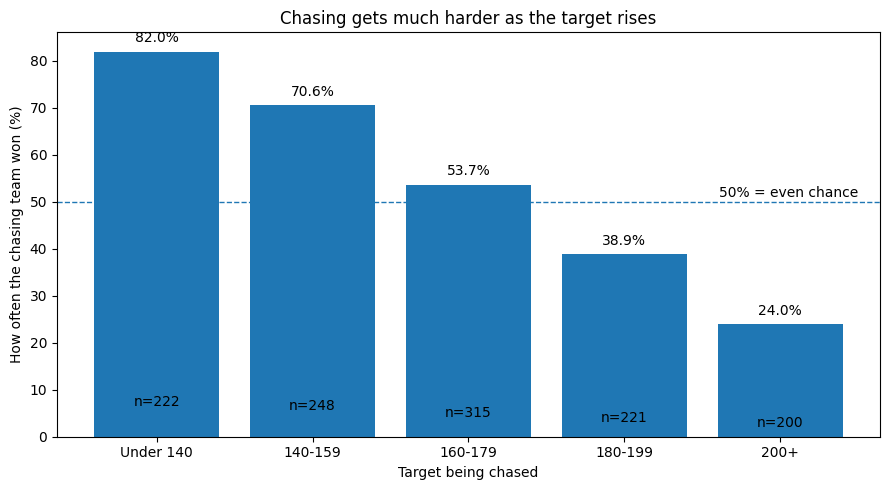

In [121]:
# H2 - Chase win rate by target band

h2_df = q("""
WITH innings_scores AS (
    SELECT
        match_id,
        innings,
        batting_team,
        SUM(total_runs) AS runs
    FROM v_ball
    GROUP BY match_id, innings, batting_team
),
match_scores AS (
    SELECT
        match_id,
        MAX(CASE WHEN innings = 1 THEN runs END) AS first_innings_runs,
        MAX(CASE WHEN innings = 2 THEN batting_team END) AS chasing_team
    FROM innings_scores
    GROUP BY match_id
)
SELECT
    CASE
        WHEN first_innings_runs < 140 THEN 'Under 140'
        WHEN first_innings_runs < 160 THEN '140-159'
        WHEN first_innings_runs < 180 THEN '160-179'
        WHEN first_innings_runs < 200 THEN '180-199'
        ELSE '200+'
    END AS target_band,
    COUNT(*) AS matches,
    ROUND(
        100.0 * AVG(
            CASE
                WHEN m.match_winner = s.chasing_team THEN 1.0
                ELSE 0.0
            END
        ),
        1
    ) AS chase_win_pct
FROM match_scores s
JOIN v_matches_clean m
    ON s.match_id = m.match_id
WHERE s.first_innings_runs IS NOT NULL
  AND s.chasing_team IS NOT NULL
  AND m.match_winner IS NOT NULL
GROUP BY target_band
ORDER BY MIN(s.first_innings_runs);
""")

bands = h2_df["target_band"]
rates = h2_df["chase_win_pct"]
counts = h2_df["matches"]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(bands, rates)

ax.set_title("Chasing gets much harder as the target rises")
ax.set_xlabel("Target being chased")
ax.set_ylabel("How often the chasing team won (%)")

ax.axhline(50, linestyle="--", linewidth=1)

ax.text(
    len(bands) - 0.5,
    51,
    "50% = even chance",
    ha="right"
)

for bar, rate, n in zip(bars, rates, counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        rate + 2,
        f"{rate:.1f}%",
        ha="center"
    )
    
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        max(2, rate * 0.08),
        f"n={int(n)}",
        ha="center"
    )

fig.tight_layout()

fig.savefig(
    FIG_DIR / "chase_win_rate_target_band.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

Chart 2 — Runs and Wickets by Phase

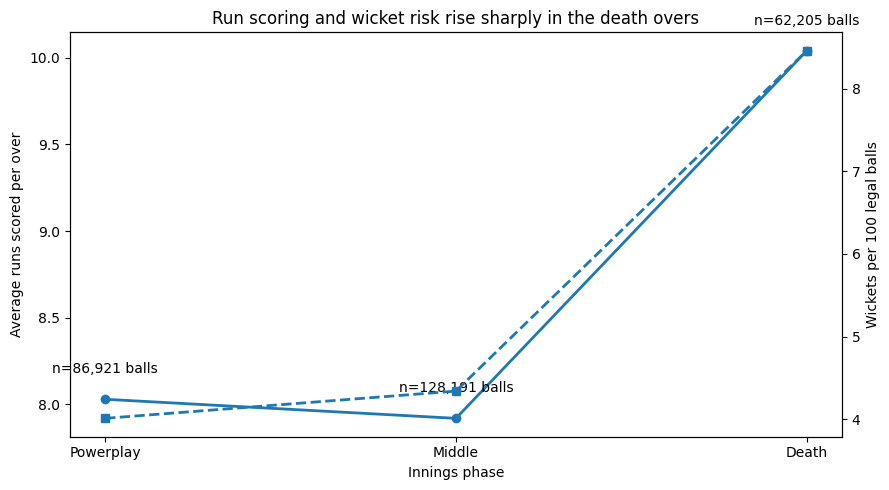

In [122]:
# C1 - Runs and wickets by innings phase
c1_df = q("""
SELECT phase,
       SUM(is_legal) AS balls,
       ROUND(6.0*SUM(total_runs)/SUM(is_legal),2) AS runs_per_over,
       ROUND(100.0*SUM(is_wicket)/SUM(is_legal),2) AS wicket_pct
FROM v_ball
GROUP BY phase
ORDER BY CASE
    WHEN phase = 'Powerplay' THEN 1
    WHEN phase = 'Middle' THEN 2
    WHEN phase = 'Death' THEN 3
END;
""")
phase = c1_df["phase"]
runs = c1_df["runs_per_over"]
wickets = c1_df["wicket_pct"]
balls = c1_df["balls"]
fig, ax1 = plt.subplots(figsize=(9, 5))
# Runs
ax1.plot(
    phase,
    runs,
    marker="o",
    linewidth=2
)
ax1.set_xlabel("Innings phase")
ax1.set_ylabel("Average runs scored per over")
# Wickets
ax2 = ax1.twinx()
ax2.plot(
    phase,
    wickets,
    marker="s",
    linestyle="--",
    linewidth=2
)
ax2.set_ylabel("Wickets per 100 legal balls")
ax1.set_title(
    "Run scoring and wicket risk rise sharply in the death overs"
)
# Add sample size
for i, n in enumerate(balls):
    ax1.text(
        i,
        runs.iloc[i] + 0.15,
        f"n={int(n):,} balls",
        ha="center"
    )
fig.tight_layout()
fig.savefig(
    FIG_DIR / "runs_wickets_by_phase.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

Chart 3 — Toss Decision

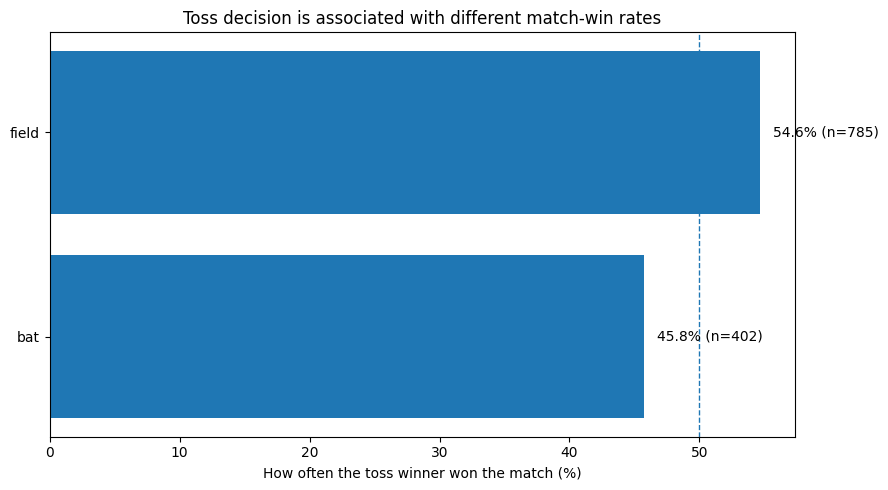

In [123]:
# G3 - Toss decision and match result
g3_df = q("""
SELECT toss_decision,
       COUNT(*) AS matches,
       SUM(
           CASE
               WHEN toss_winner = match_winner THEN 1
               ELSE 0
           END
       ) AS toss_winner_won,
       ROUND(
           100.0 * SUM(
               CASE
                   WHEN toss_winner = match_winner THEN 1
                   ELSE 0
               END
           ) / COUNT(*), 2
       ) AS pct
FROM matches_clean
WHERE result = 'win'
GROUP BY toss_decision;
""")
labels = g3_df["toss_decision"]
rates = g3_df["pct"]
counts = g3_df["matches"]
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(labels, rates)
# 50% reference
ax.axvline(50, linestyle="--", linewidth=1)
ax.set_title(
    "Toss decision is associated with different match-win rates"
)
ax.set_xlabel(
    "How often the toss winner won the match (%)"
)
for bar, rate, n in zip(bars, rates, counts):
    ax.text(
        rate + 1,
        bar.get_y() + bar.get_height()/2,
        f"{rate:.1f}% (n={int(n)})",
        va="center"
    )
fig.tight_layout()
fig.savefig(
    FIG_DIR / "toss_split.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

Chart 4 — Top Grounds by Number of Matches

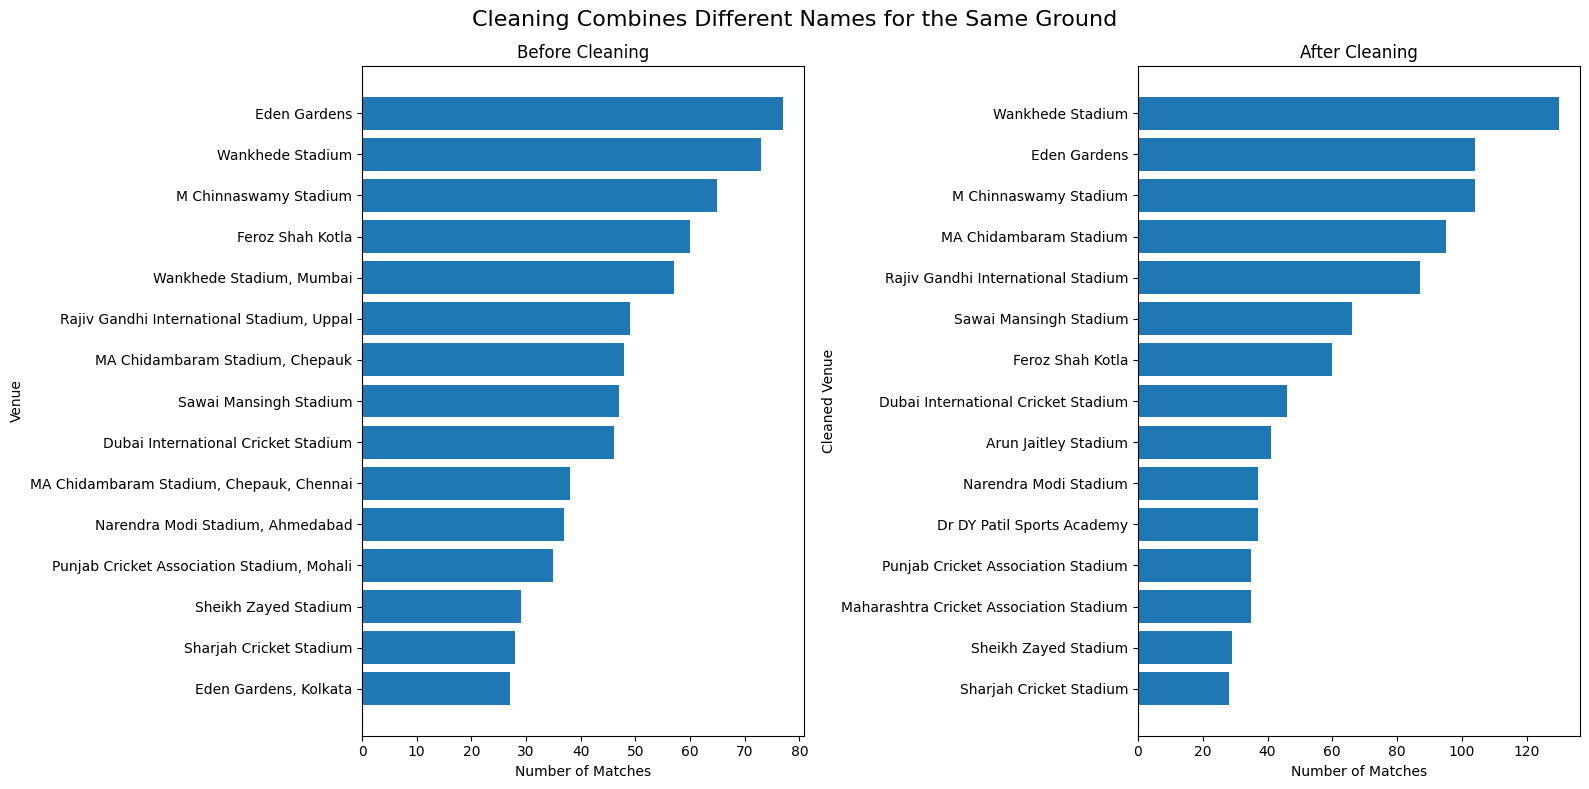

In [124]:
# ============================================
# I1 - Before vs After Venue Cleaning Chart
# ============================================

i1_raw_df = q("""
SELECT venue, COUNT(DISTINCT match_id) AS matches
FROM matches
GROUP BY venue
ORDER BY matches DESC
LIMIT 15;
""")

i1_clean_df = q("""
SELECT venue_clean, COUNT(DISTINCT match_id) AS matches
FROM v_matches_clean
GROUP BY venue_clean
ORDER BY matches DESC
LIMIT 15;
""")

raw = i1_raw_df.sort_values("matches")
clean = i1_clean_df.sort_values("matches")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].barh(raw["venue"], raw["matches"])
axes[0].set_title("Before Cleaning")
axes[0].set_xlabel("Number of Matches")
axes[0].set_ylabel("Venue")

axes[1].barh(clean["venue_clean"], clean["matches"])
axes[1].set_title("After Cleaning")
axes[1].set_xlabel("Number of Matches")
axes[1].set_ylabel("Cleaned Venue")

fig.suptitle(
    "Cleaning Combines Different Names for the Same Ground",
    fontsize=16
)

fig.tight_layout()

fig.savefig(
    FIG_DIR / "venue_before_after.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

Chart 5 — Specialism Chart

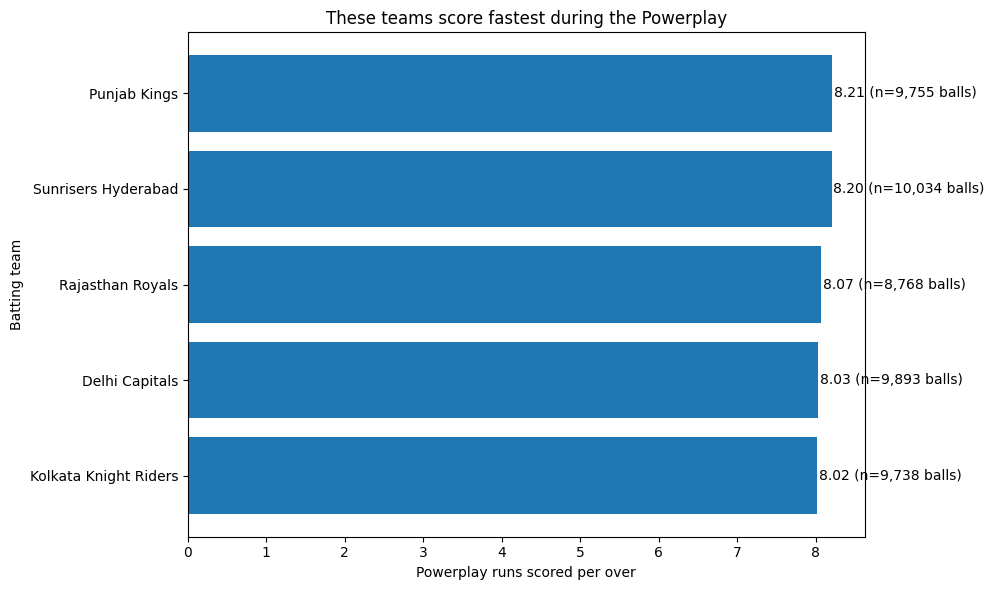

In [125]:
# J3 - Which team scores fastest in the Powerplay?
j3_df = q("""
SELECT batting_team,
       SUM(is_legal) AS balls,
       ROUND(
           6.0*SUM(total_runs)/SUM(is_legal),
           2
       ) AS pp_run_rate
FROM v_ball
WHERE phase = 'Powerplay'
GROUP BY batting_team
HAVING SUM(is_legal) >= 3000
ORDER BY pp_run_rate DESC
LIMIT 5;
""")
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(
    j3_df["batting_team"][::-1],
    j3_df["pp_run_rate"][::-1]
)
ax.set_title(
    "These teams score fastest during the Powerplay"
)
ax.set_xlabel(
    "Powerplay runs scored per over"
)
ax.set_ylabel(
    "Batting team"
)
for bar, rate, n in zip(
    bars,
    j3_df["pp_run_rate"][::-1],
    j3_df["balls"][::-1]
):
    ax.text(
        rate + 0.02,
        bar.get_y() + bar.get_height()/2,
        f"{rate:.2f} (n={int(n):,} balls)",
        va="center"
    )
fig.tight_layout()
fig.savefig(
    FIG_DIR / "powerplay_team_run_rate.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

6. Check that all 5 charts were saved

In [126]:
# Check saved charts
for file in FIG_DIR.glob("*.png"):
    print(file.name)

chase_win_rate_target_band.png
powerplay_team_run_rate.png
runs_wickets_by_phase.png
toss_split.png
venue_before_after.png


In [127]:
c1_df["balls"].sum()

np.int64(277317)

# Ipl ipynb Charts


In [128]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

con = sqlite3.connect(r"..\data\raw\ipl.db")                       
pd.read_csv(r"..\data\raw\Tables\matches.csv").to_sql("matches", con, if_exists="replace", index=False)  # add match table

print("tables:", pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con).name.tolist())

tables: ['deliveries', 'teams', 'players', 'venues', 'matches_clean', 'matches']


1. Chase win rate by first-innings target (H2) — bar

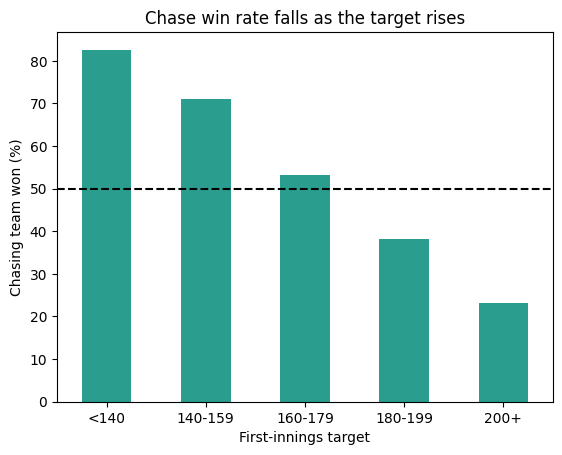

In [129]:
df = pd.read_sql("""
    WITH first_inn AS (SELECT match_id, SUM(total_runs) target
                       FROM deliveries WHERE is_super_over=0 AND innings=1 GROUP BY match_id),
         chaser AS (SELECT match_id, MIN(batting_team) team2
                    FROM deliveries WHERE is_super_over=0 AND innings=2 GROUP BY match_id)
    SELECT CASE WHEN target<140 THEN '<140' WHEN target<160 THEN '140-159'
                WHEN target<180 THEN '160-179' WHEN target<200 THEN '180-199'
                ELSE '200+' END AS target_band,
           ROUND(100.0*AVG(CASE WHEN c.team2=m.match_winner THEN 1 ELSE 0 END),1) AS win_pct
    FROM first_inn f JOIN chaser c USING(match_id) JOIN matches m USING(match_id)
    WHERE m.result='win'
    GROUP BY target_band ORDER BY MIN(target)
""", con, index_col="target_band")
df.plot(kind="bar", rot=0, legend=False, color="#2a9d8f",
        title="Chase win rate falls as the target rises",
        xlabel="First-innings target", ylabel="Chasing team won (%)")
plt.axhline(50, ls="--", c="k"); plt.show()

2. Runs per over by phase (C1) — bar

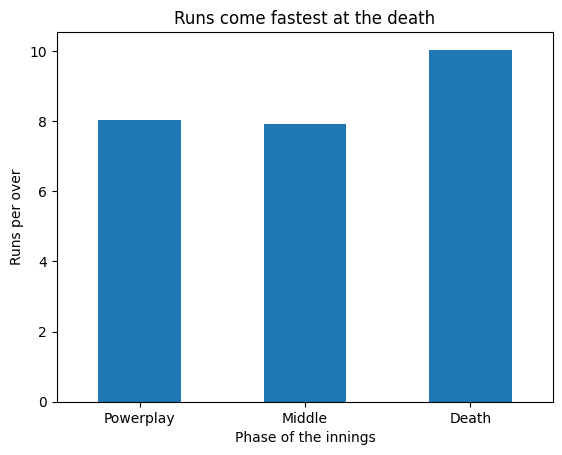

In [130]:
df = pd.read_sql("""
    SELECT CASE WHEN over_number<=5 THEN 'Powerplay'
                WHEN over_number<=14 THEN 'Middle' ELSE 'Death' END AS phase,
           SUM(total_runs)*6.0 / SUM(CASE WHEN is_wide_ball=0 AND is_no_ball=0 THEN 1 ELSE 0 END) AS runs_per_over
    FROM deliveries WHERE is_super_over=0
    GROUP BY phase ORDER BY MIN(over_number)
""", con, index_col="phase")
df.plot(kind="bar", rot=0, legend=False, color="#1f77b4",
        title="Runs come fastest at the death",
        xlabel="Phase of the innings", ylabel="Runs per over")
plt.show()

3. How captains use the toss (G3) — pie

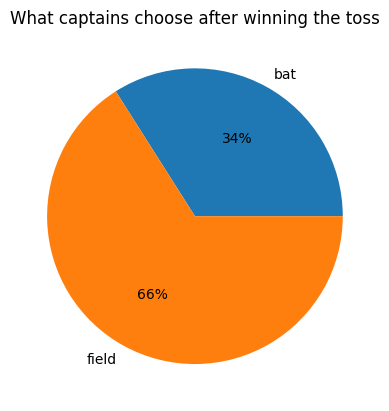

In [131]:
df = pd.read_sql("""
    SELECT toss_decision, COUNT(*) AS matches
    FROM matches GROUP BY toss_decision
""", con, index_col="toss_decision")
df.plot(kind="pie", y="matches", autopct="%.0f%%", legend=False, ylabel="",
        title="What captains choose after winning the toss")
plt.show()

4. Pace against spin (E) — bar

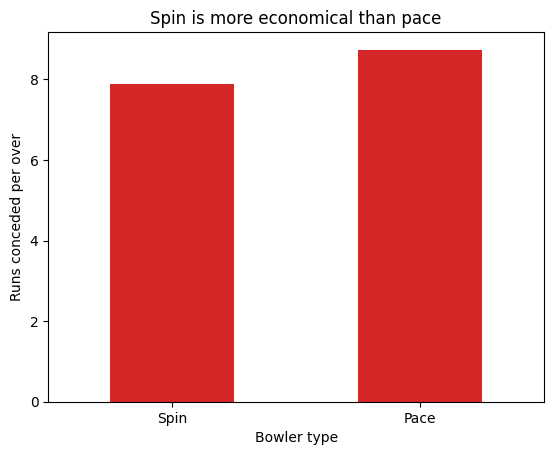

In [132]:
df = pd.read_sql("""
    SELECT CASE WHEN LOWER(bowler_type) LIKE '%break%' OR LOWER(bowler_type) LIKE '%orthodox%'
                  OR LOWER(bowler_type) LIKE '%wrist spin%' OR LOWER(bowler_type) LIKE '%googly%'
                THEN 'Spin' ELSE 'Pace' END AS bowler_kind,
           SUM(total_runs)*6.0 / SUM(CASE WHEN is_wide_ball=0 AND is_no_ball=0 THEN 1 ELSE 0 END) AS economy
    FROM deliveries WHERE is_super_over=0 AND TRIM(bowler_type)<>''
    GROUP BY bowler_kind ORDER BY bowler_kind DESC
""", con, index_col="bowler_kind")
df.plot(kind="bar", rot=0, legend=False, color=["#d62728","#1f77b4"],
        title="Spin is more economical than pace",
        xlabel="Bowler type", ylabel="Runs conceded per over")
plt.show()

5. First-innings scores by season (L) — line

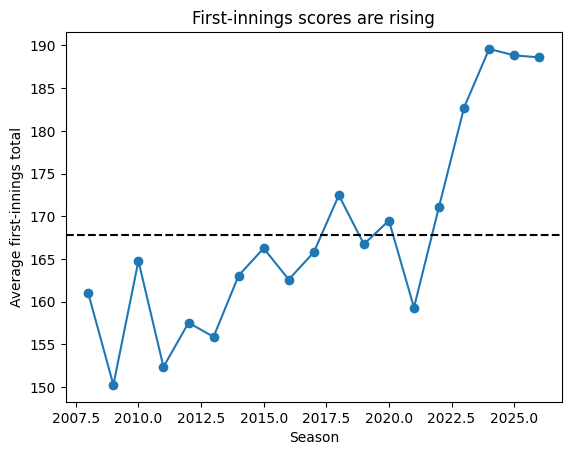

In [133]:
df = pd.read_sql("""
    SELECT season_id, AVG(total) AS avg_first_innings FROM (
        SELECT season_id, match_id, SUM(total_runs) AS total
        FROM deliveries WHERE is_super_over=0 AND innings=1
        GROUP BY season_id, match_id)
    GROUP BY season_id ORDER BY season_id
""", con, index_col="season_id")
df.plot(kind="line", marker="o", legend=False, color="#1f77b4",
        title="First-innings scores are rising",
        xlabel="Season", ylabel="Average first-innings total")
plt.axhline(df.avg_first_innings.mean(), ls="--", c="k"); plt.show()

6. Left-hand against right-hand batters (A8) — bar

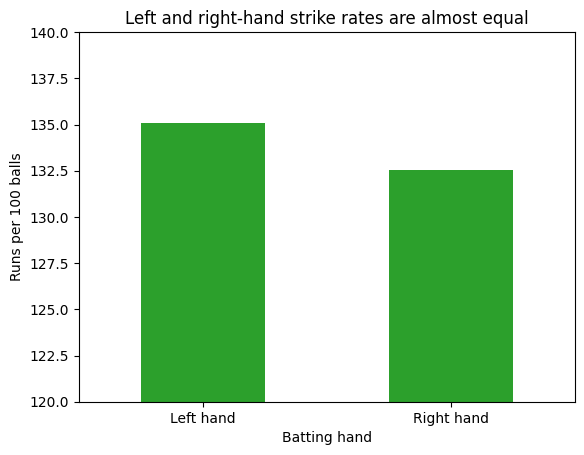

In [134]:
df = pd.read_sql("""
    SELECT CASE WHEN LOWER(batsman_type) LIKE '%left%' THEN 'Left hand' ELSE 'Right hand' END AS batting_hand,
           SUM(batter_runs)*100.0 / SUM(CASE WHEN is_wide_ball=0 AND is_no_ball=0 THEN 1 ELSE 0 END) AS strike_rate
    FROM deliveries WHERE is_super_over=0 AND TRIM(batsman_type)<>''
    GROUP BY batting_hand
""", con, index_col="batting_hand")
df.plot(kind="bar", rot=0, legend=False, ylim=(120,140), color=["#2ca02c","#1f77b4"],
        title="Left and right-hand strike rates are almost equal",
        xlabel="Batting hand", ylabel="Runs per 100 balls")
plt.show()

7. How wickets fall (K) — horizontal bar

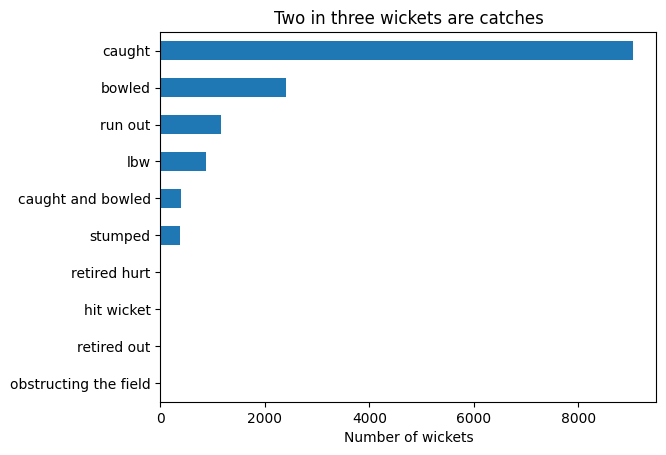

In [135]:
df = pd.read_sql("""
    SELECT wicket_kind, COUNT(*) AS wickets
    FROM deliveries WHERE is_super_over=0 AND is_wicket=1 AND TRIM(COALESCE(wicket_kind,''))<>''
    GROUP BY wicket_kind ORDER BY wickets
""", con, index_col="wicket_kind")
df.plot(kind="barh", legend=False, color="#1f77b4",
        title="Two in three wickets are catches",
        xlabel="Number of wickets", ylabel="")
plt.show()

8. Top 10 run scorers — horizontal bar

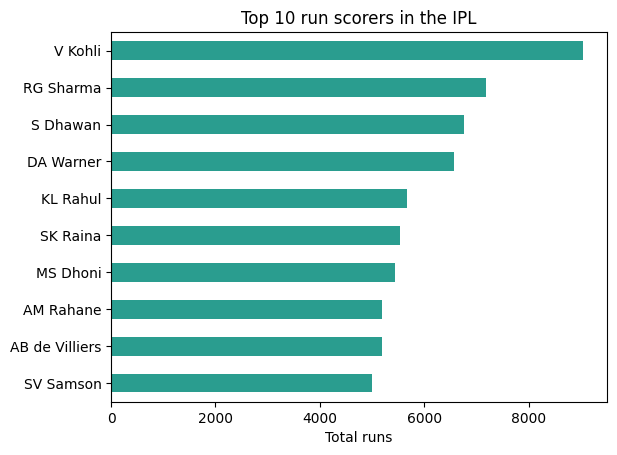

In [136]:
df = pd.read_sql("""
    SELECT * FROM (
        SELECT batter, SUM(batter_runs) AS runs
        FROM deliveries GROUP BY batter ORDER BY runs DESC LIMIT 10)
    ORDER BY runs
""", con, index_col="batter")
df.plot(kind="barh", legend=False, color="#2a9d8f",
        title="Top 10 run scorers in the IPL",
        xlabel="Total runs", ylabel="")
plt.show()

9. Top 10 wicket takers — horizontal bar

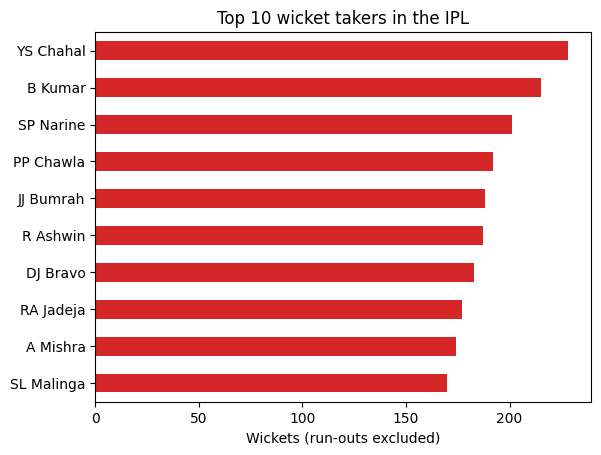

In [137]:
df = pd.read_sql("""
    SELECT * FROM (
        SELECT bowler, COUNT(*) AS wickets
        FROM deliveries
        WHERE is_wicket=1 AND wicket_kind NOT IN ('run out','retired hurt','retired out','obstructing the field')
        GROUP BY bowler ORDER BY wickets DESC LIMIT 10)
    ORDER BY wickets
""", con, index_col="bowler")
df.plot(kind="barh", legend=False, color="#d62728",
        title="Top 10 wicket takers in the IPL",
        xlabel="Wickets (run-outs excluded)", ylabel="")
plt.show()

10. Scoring over by over (1-20) — line

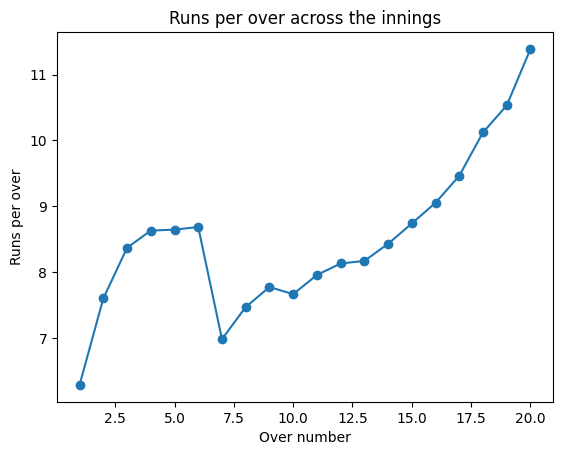

In [138]:
df = pd.read_sql("""
    SELECT over_number+1 AS over_no,
           SUM(total_runs)*6.0 / SUM(CASE WHEN is_wide_ball=0 AND is_no_ball=0 THEN 1 ELSE 0 END) AS runs_per_over
    FROM deliveries WHERE is_super_over=0
    GROUP BY over_number ORDER BY over_number
""", con, index_col="over_no")
df.plot(kind="line", marker="o", legend=False, color="#1f77b4",
        title="Runs per over across the innings",
        xlabel="Over number", ylabel="Runs per over")
plt.show()

11. Where the runs come from — pie

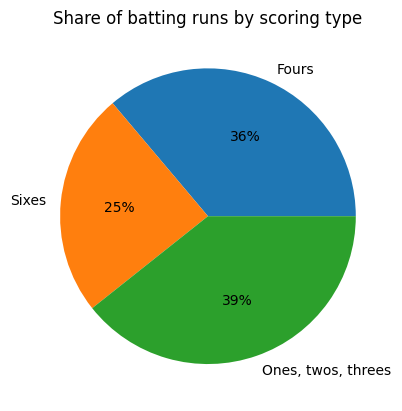

In [139]:
df = pd.read_sql("""
    SELECT 'Fours' AS run_type, SUM(CASE WHEN batter_runs=4 THEN 4 ELSE 0 END) AS runs FROM deliveries WHERE is_super_over=0
    UNION ALL SELECT 'Sixes', SUM(CASE WHEN batter_runs=6 THEN 6 ELSE 0 END) FROM deliveries WHERE is_super_over=0
    UNION ALL SELECT 'Ones, twos, threes', SUM(CASE WHEN batter_runs NOT IN (4,6) THEN batter_runs ELSE 0 END) FROM deliveries WHERE is_super_over=0
""", con, index_col="run_type")
df.plot(kind="pie", y="runs", autopct="%.0f%%", legend=False, ylabel="",
        title="Share of batting runs by scoring type")
plt.show()

12. Venue names before and after cleaning (I1) — bar

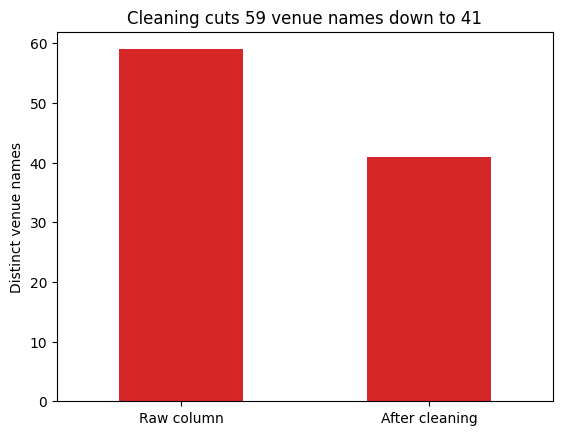

In [140]:
df = pd.read_sql("""
    SELECT 'Raw column' AS stage, COUNT(DISTINCT venue) AS venue_count FROM matches
    UNION ALL
    SELECT 'After cleaning',
           COUNT(DISTINCT CASE WHEN INSTR(venue, ',') > 0                         -- name has a city after a comma
                               THEN TRIM(REPLACE(SUBSTR(venue, 1, INSTR(venue, ',') - 1), '.', ' '))
                               ELSE TRIM(REPLACE(venue, '.', ' ')) END)           -- name has no comma
    FROM matches
""", con, index_col="stage")
df.plot(kind="bar", rot=0, legend=False, color=["#d62728","#2ca02c"],
        title="Cleaning cuts 59 venue names down to 41",
        xlabel="", ylabel="Distinct venue names")
plt.show()

In [141]:
con.close()